# Deep Learning
The project starts with an Artificial Neural Network (ANN) for Wine dataset classification, explores image-processing techniques using OpenCV, builds a Convolutional Neural Network (CNN) for handwritten digit recognition, applies a Recurrent Neural Network (RNN) to IMDB sentiment analysis, and explores Transformer-based natural language processing.


# Step 1: ANN — Artificial Neural Network

# Import All Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

# Import the Wine dataset
from sklearn.datasets import load_wine

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

from tensorflow.keras.utils import to_categorical

# Import ANN model and layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

##  Set random seeds for reproducible results

In [3]:
np.random.seed(42)
tf.random.set_seed(42)

# Set the graph style
sns.set_theme(style="whitegrid")

# 1.1  Data Loading & Preprocessing

## Load Dataset

In [4]:
wine_data = load_wine(as_frame=True)

In [5]:
df = wine_data.frame.copy()

## Dataset Information

In [6]:
print("Dataset Shape:", df.shape)

Dataset Shape: (178, 14)


In [7]:
display(df.head())

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [8]:
print("Columns:", df.columns.tolist())

Columns: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'target']


In [9]:
print(df.dtypes)

alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object


## Check missing value

In [10]:
print(df.isnull().sum())

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64


In [11]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


## Descriptive

In [12]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


## Class distribution

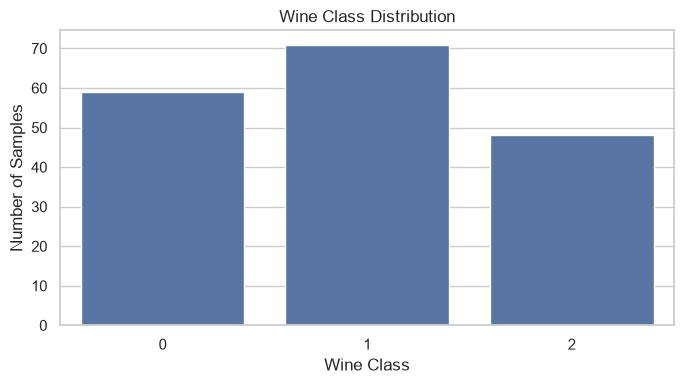

target
0    59
1    71
2    48
Name: count, dtype: int64


In [13]:
# Count samples belonging to each class
class_counts = df["target"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("Wine Class Distribution")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

print(class_counts)

## Feature Range Coparison

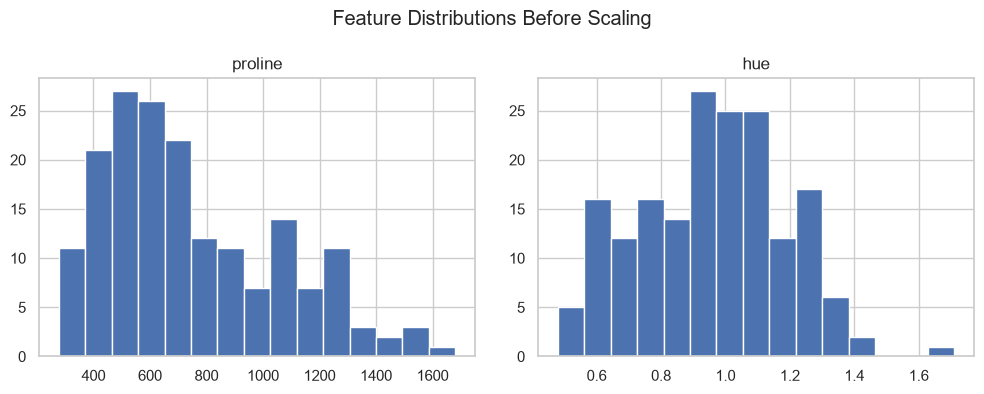

In [ ]:
features = ["proline", "hue"]

df[features].hist(figsize=(10, 4), bins=15)

plt.suptitle("Feature Distributions Before Scaling")
plt.tight_layout()
plt.show()


In [19]:
# Print minimum and maximum values
print(df[features].agg(["min", "max"]).T)

            min      max
proline  278.00  1680.00
hue        0.48     1.71


## Feature and Target

In [20]:
X = df.drop(columns=["target"])
y = df["target"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (178, 13)
y Shape: (178,)


In [21]:
# Display first five target labels
print("Target Labels:", y.head().tolist())

Target Labels: [0, 0, 0, 0, 0]


## Train-Test Split

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,                    
    y,                    
    test_size=0.20,       
    random_state=42,      
    stratify=y          
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 142
Testing Samples: 36


## Feature Shape

In [23]:
print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)

X_train Shape: (142, 13)
X_test Shape: (36, 13)


## Feature Scaling

In [24]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [25]:
print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

# Check means of the first five scaled features
print("Scaled Feature Means:")
print(np.round(X_train_scaled.mean(axis=0)[:5], 3))

Scaled Training Shape: (142, 13)
Scaled Testing Shape: (36, 13)
Scaled Feature Means:
[ 0.  0. -0.  0.  0.]


In [26]:
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


## One-Hot Encoding

In [28]:
y_train_encoded = to_categorical(y_train, num_classes=3)
y_test_encoded = to_categorical(y_test, num_classes=3)

## Encoded shape

In [29]:
print("Training Labels Shape:", y_train_encoded.shape)
print("Testing Labels Shape:", y_test_encoded.shape)

Training Labels Shape: (142, 3)
Testing Labels Shape: (36, 3)


## Display five encoded examples

In [30]:
for i in range(5):
    print(
        "Original:", y_train.iloc[i],
        "Encoded:", y_train_encoded[i]
    )

Original: 0 Encoded: [1. 0. 0.]
Original: 0 Encoded: [1. 0. 0.]
Original: 0 Encoded: [1. 0. 0.]
Original: 0 Encoded: [1. 0. 0.]
Original: 2 Encoded: [0. 0. 1.]


# 1.2 Build The ANN Model

In [31]:
model = Sequential([
    Input(shape=(13,)),

    Dense(16, activation="relu"),

    Dense(8, activation="relu"),

    Dense(3, activation="softmax")
])

## Compile Model

In [32]:
model.compile(
    optimizer="adam",                  
    loss="categorical_crossentropy",    
    metrics=["accuracy"]                
)

# Display the model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 387 (1.51 KB)

 Trainable params: 387 (1.51 KB)

 Non-trainable params: 0 (0.00 B)

## Calculate First Hidden Layer Parameters

In [33]:
weights = 13 * 16
biases = 16

total_parameters = weights + biases

# Display the calculation
print("Weights:", weights)
print("Biases:", biases)
print("Total Parameters:", total_parameters)

Weights: 208
Biases: 16
Total Parameters: 224


# 1.3 Train & Evaluate

## Train The ANN

In [34]:
# Train the ANN model
history = model.fit(
    X_train_scaled,          
    y_train_encoded,         
    epochs=60,              
    batch_size=8,            
    validation_split=0.2,    
    verbose=1
    )              

Epoch 1/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.0354 - loss: 1.5953 - val_accuracy: 0.0345 - val_loss: 1.4325
Epoch 2/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0796 - loss: 1.3965 - val_accuracy: 0.1034 - val_loss: 1.2783
Epoch 3/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1681 - loss: 1.2442 - val_accuracy: 0.2069 - val_loss: 1.1623
Epoch 4/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3097 - loss: 1.1312 - val_accuracy: 0.2759 - val_loss: 1.0720
Epoch 5/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5664 - loss: 1.0429 - val_accuracy: 0.5517 - val_loss: 0.9980
Epoch 6/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7257 - loss: 0.9695 - val_accuracy: 0.7586 - val_loss: 0.9366
Epoch 7/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7699 - loss: 0.9029 - val_accuracy: 0.7931 - val_loss: 0.8822
Epoch 8/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8319 - loss: 0.8378 - val_accuracy: 0.8276 - v

## Plot Accuracy

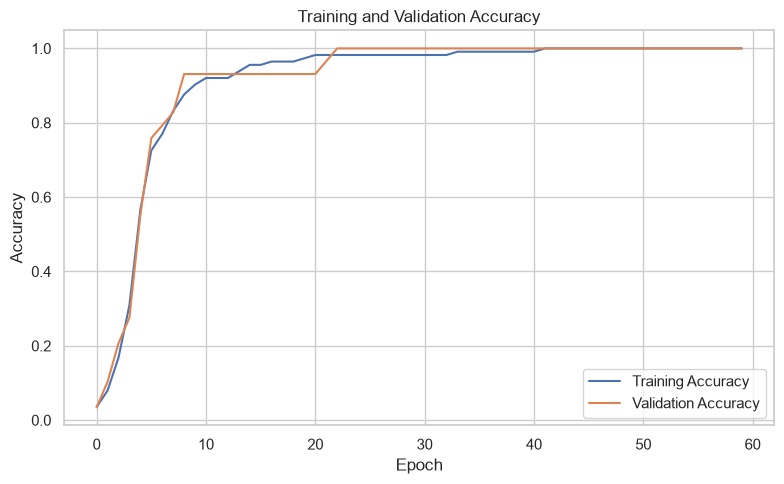

In [35]:
plt.figure(figsize=(8, 5))
plt.plot(
    history.history["accuracy"],
    label="Training Accuracy")

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Plot Loss

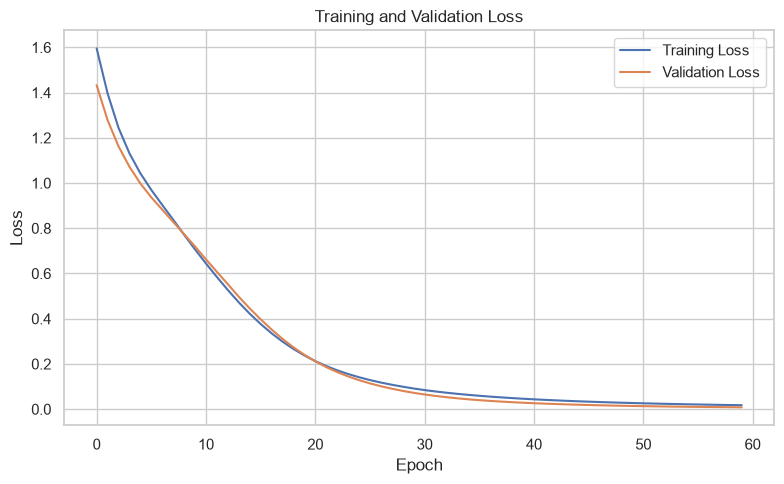

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss")

plt.plot(
    history.history["val_loss"],
    label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Predict test data

In [37]:
y_probabilities = model.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_probabilities, axis=1)

y_test_labels = y_test.to_numpy()

for i in range(5):
    print(
        "Actual:", y_test_labels[i],
        "Predicted:", y_pred[i],
        "Probabilities:", np.round(y_probabilities[i], 3)
    )

Actual: 0 Predicted: 0 Probabilities: [1. 0. 0.]
Actual: 2 Predicted: 2 Probabilities: [0.003 0.471 0.526]
Actual: 0 Predicted: 0 Probabilities: [0.998 0.001 0.001]
Actual: 1 Predicted: 1 Probabilities: [0.135 0.864 0.001]
Actual: 1 Predicted: 1 Probabilities: [0.01  0.97  0.021]


## Test Accuracy

In [38]:
test_accuracy = accuracy_score(y_test_labels, y_pred)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 100.00%


## Classification Report

In [39]:
print("Classification Report:")

print(
    classification_report(
        y_test_labels,              
        y_pred,                     
        labels=[0, 1, 2],            
        target_names=wine_data.target_names,
        zero_division=0
    )
)

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



## Confusion Matrix Heatmap

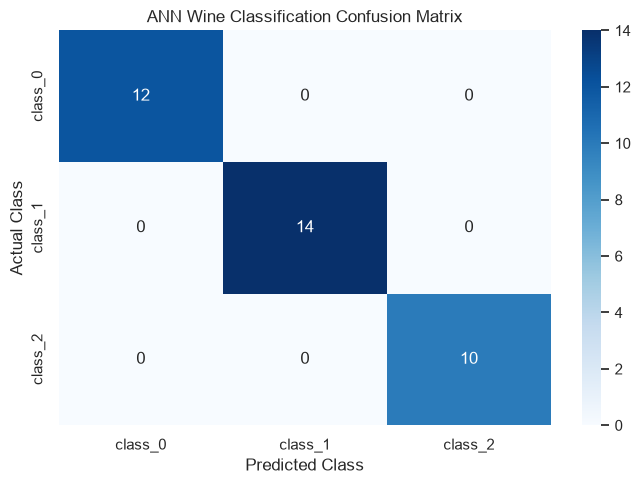

[[12  0  0]
 [ 0 14  0]
 [ 0  0 10]]


In [40]:
cm = confusion_matrix(
    y_test_labels,
    y_pred,
    labels=[0, 1, 2])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,                      
    fmt="d",                          
    cmap="Blues",                    
    xticklabels=wine_data.target_names,
    yticklabels=wine_data.target_names)

plt.title("ANN Wine Classification Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

print(cm)

## Check Target Accuracy

In [41]:
if test_accuracy >= 0.94:

    print("Target achieved: Accuracy is 94% or above.")

else:

    print("Target not achieved in this run.")

print("Correct Predictions:", np.sum(y_test_labels == y_pred))
print("Total Test Samples:", len(y_test_labels))

Target achieved: Accuracy is 94% or above.
Correct Predictions: 36
Total Test Samples: 36


# 1.4 Save & Reflect

## Save The Trained Model

In [42]:
model.save("ann_wine_model.h5")

print("Model saved successfully as ann_wine_model.h5")

Model saved successfully as ann_wine_model.h5


## Load And Test The Saved Model

In [43]:
loaded_model = tf.keras.models.load_model("ann_wine_model.h5")

loaded_probabilities = loaded_model.predict(
    X_test_scaled,
    verbose=0)

loaded_predictions = np.argmax(loaded_probabilities, axis=1)

loaded_accuracy = accuracy_score(
    y_test_labels,
    loaded_predictions)

# Display loaded model accuracy
print(f"Loaded Model Accuracy: {loaded_accuracy * 100:.2f}%")

Loaded Model Accuracy: 100.00%


# Conclusion
In this project, I built an Artificial Neural Network (ANN) using the Wine Recognition dataset to classify wine into three different categories based on 13 chemical features. I performed data preprocessing, handled feature scaling using StandardScaler, and converted class labels into one-hot encoded vectors. I developed a neural network with two hidden layers using ReLU activation and an output layer using Softmax. The model was trained using the Adam optimizer and categorical crossentropy loss. Finally, I evaluated its performance using test accuracy, a classification report, and a confusion matrix. The trained model was saved as ann_wine_model.h5 for future use.

**Result**: The model's actual test accuracy was evaluated to measure its classification performance.

#  Step 2:OpenCV — Colour, Morphology & Face Detection

In [ ]:
import cv2
from pathlib import Path

# Import sample images
from skimage import data

# Display OpenCV version
print("OpenCV Version:", cv2.__version__)

OpenCV Version: 5.0.0


# 2.1 Load & Display 

## Load 5 Images

In [ ]:
astronaut_rgb = data.astronaut()

coffee_rgb = data.coffee()       # Coffee image

cat_rgb = data.chelsea()         # Cat image

rocket_rgb = data.rocket()       # Rocket image

from pathlib import Path
my_image_path = Path("my_image.jpg")

if my_image_path.exists():

    own_bgr = cv2.imread(str(my_image_path))

    own_rgb = cv2.cvtColor(own_bgr, cv2.COLOR_BGR2RGB)

    own_name = "My Image"

else:
    own_rgb = data.chelsea()

    own_name = "Cat Fallback"

image_items = [
    ("Astronaut", astronaut_rgb),
    ("Coffee", coffee_rgb),
    ("Cat", cat_rgb),
    ("Rocket", rocket_rgb),
    (own_name, own_rgb)
]

print("Total Images:", len(image_items))

for name, image in image_items:
    print(name, image.shape)

Total Images: 5
Astronaut (512, 512, 3)
Coffee (400, 600, 3)
Cat (300, 451, 3)
Rocket (427, 640, 3)
Cat Fallback (300, 451, 3)


## Display The Original Image

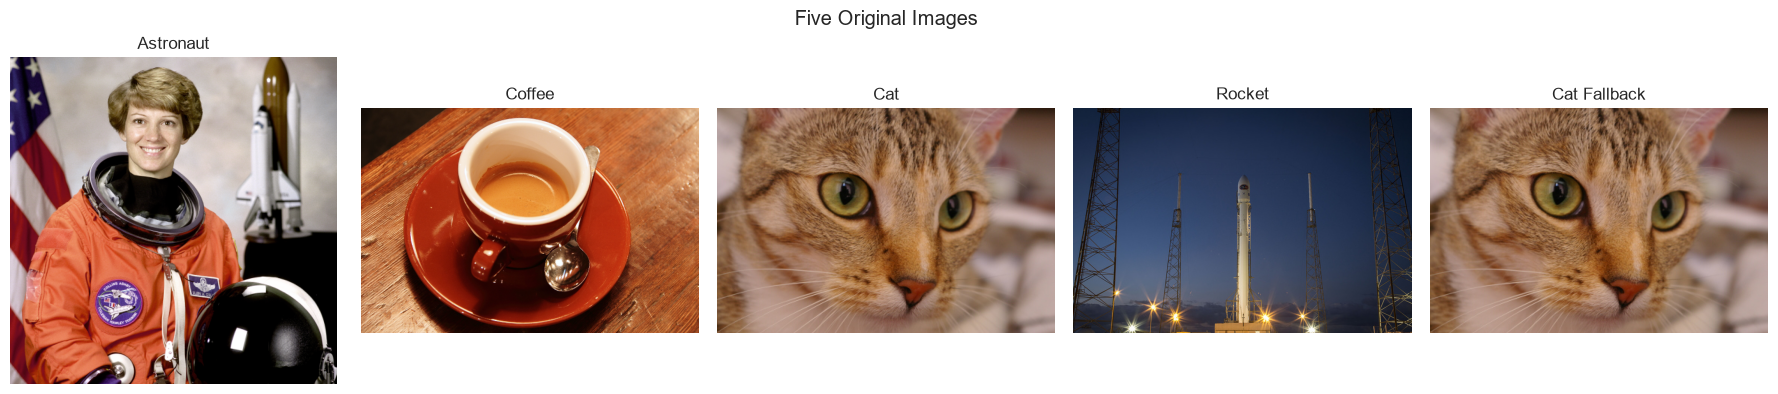

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for axis, (name, image) in zip(axes, image_items):

    axis.imshow(image)
    axis.set_title(name)
    axis.axis("off")

plt.suptitle("Five Original Images")
plt.tight_layout()
plt.show()

## Print Imges Properties

In [ ]:
for name, image in image_items:

    print("\nImage:", name)
    print("Shape:", image.shape)

    print("Data Type:", image.dtype)

    print("Minimum:", image.min())
    print("Maximum:", image.max())

    print("Mean Brightness:", round(float(image.mean()), 2))


Image: Astronaut
Shape: (512, 512, 3)
Data Type: uint8
Minimum: 0
Maximum: 255
Mean Brightness: 114.6

Image: Coffee
Shape: (400, 600, 3)
Data Type: uint8
Minimum: 0
Maximum: 255
Mean Brightness: 98.62

Image: Cat
Shape: (300, 451, 3)
Data Type: uint8
Minimum: 0
Maximum: 231
Mean Brightness: 115.31

Image: Rocket
Shape: (427, 640, 3)
Data Type: uint8
Minimum: 0
Maximum: 255
Mean Brightness: 65.28

Image: Cat Fallback
Shape: (300, 451, 3)
Data Type: uint8
Minimum: 0
Maximum: 231
Mean Brightness: 115.31


# 2.2 Preprocessing Operations

## Convert to BGR & resize to 256*256

In [ ]:
image_names = []
original_bgr_images = []

for name, image_rgb in image_items:

    image_bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)

    resized_image = cv2.resize(image_bgr, (256, 256))

    image_names.append(name)

    original_bgr_images.append(resized_image)

for name, image in zip(image_names, original_bgr_images):
    print(name, image.shape)

Astronaut (256, 256, 3)
Coffee (256, 256, 3)
Cat (256, 256, 3)
Rocket (256, 256, 3)
Cat Fallback (256, 256, 3)


## Convert BGR to HSV 

In [ ]:
hsv_images = []

for image in original_bgr_images:

    hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    hsv_images.append(hsv_image)

for name, image in zip(image_names, hsv_images):
    print(name, "HSV Shape:", image.shape)

Astronaut HSV Shape: (256, 256, 3)
Coffee HSV Shape: (256, 256, 3)
Cat HSV Shape: (256, 256, 3)
Rocket HSV Shape: (256, 256, 3)
Cat Fallback HSV Shape: (256, 256, 3)


## Display the HSV conversions

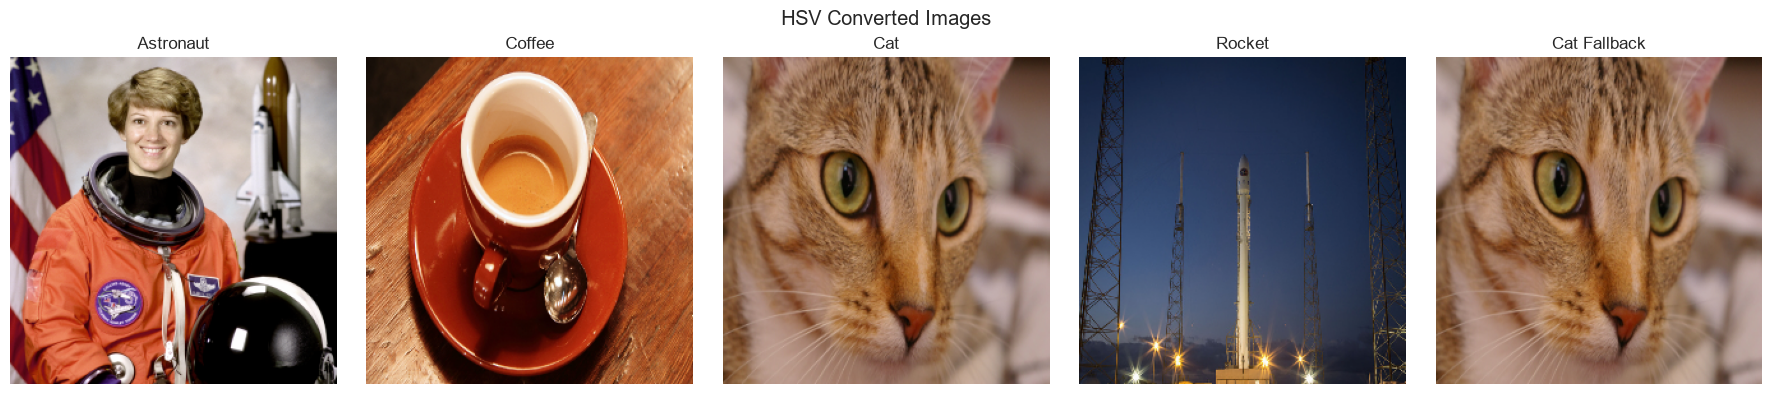

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for axis, name, image_hsv in zip(axes, image_names, hsv_images):

    image_bgr = cv2.cvtColor(image_hsv, cv2.COLOR_HSV2BGR)

    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    axis.imshow(image_rgb)

    axis.set_title(name)

    axis.axis("off")

plt.suptitle("HSV Converted Images")
plt.tight_layout()
plt.show()

## Create a blue colour mask

In [ ]:
lower_blue = np.array([90, 60, 40], dtype=np.uint8)

upper_blue = np.array([135, 255, 255], dtype=np.uint8)

colour_masks = []

for image_hsv in hsv_images:

    mask = cv2.inRange(image_hsv, lower_blue, upper_blue)

    colour_masks.append(mask)

for name, mask in zip(image_names, colour_masks):
    print(name, "Selected Pixels:", np.count_nonzero(mask))

Astronaut Selected Pixels: 1721
Coffee Selected Pixels: 1
Cat Selected Pixels: 7
Rocket Selected Pixels: 50731
Cat Fallback Selected Pixels: 7


## Display the Mask with Bitwise_and
* The mask keeps the original colour where pixels match the selected blue range. Other pixels become black

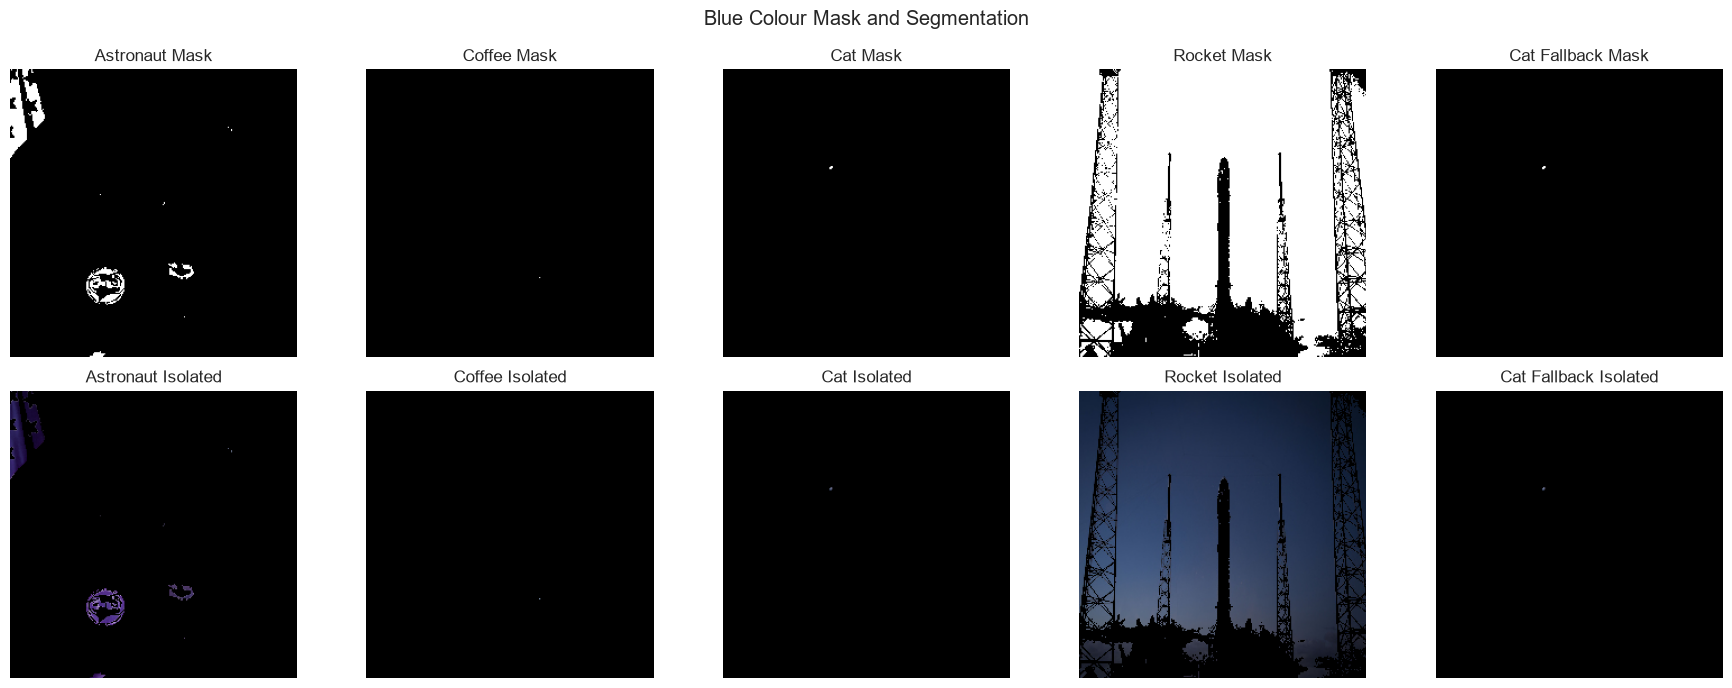

In [ ]:
masked_colour_images = []

for image, mask in zip(original_bgr_images, colour_masks):

    masked_image = cv2.bitwise_and(image, image, mask=mask)

    masked_colour_images.append(masked_image)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for axis, name, mask in zip(axes[0], image_names, colour_masks):

    axis.imshow(mask, cmap="gray")
    axis.set_title(name + " Mask")
    axis.axis("off")

for axis, name, image in zip(axes[1], image_names, masked_colour_images):

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axis.imshow(image_rgb)

    axis.set_title(name + " Isolated")
    axis.axis("off")

plt.suptitle("Blue Colour Mask and Segmentation")
plt.tight_layout()
plt.show()

## Morphology using erosion and dilation
**Erosion** shrinks white regions and may remove small white specks. 
**Dilation** expands white regions. 

Erosion followed by dilation is called opening and is often used to clean small foreground noise.


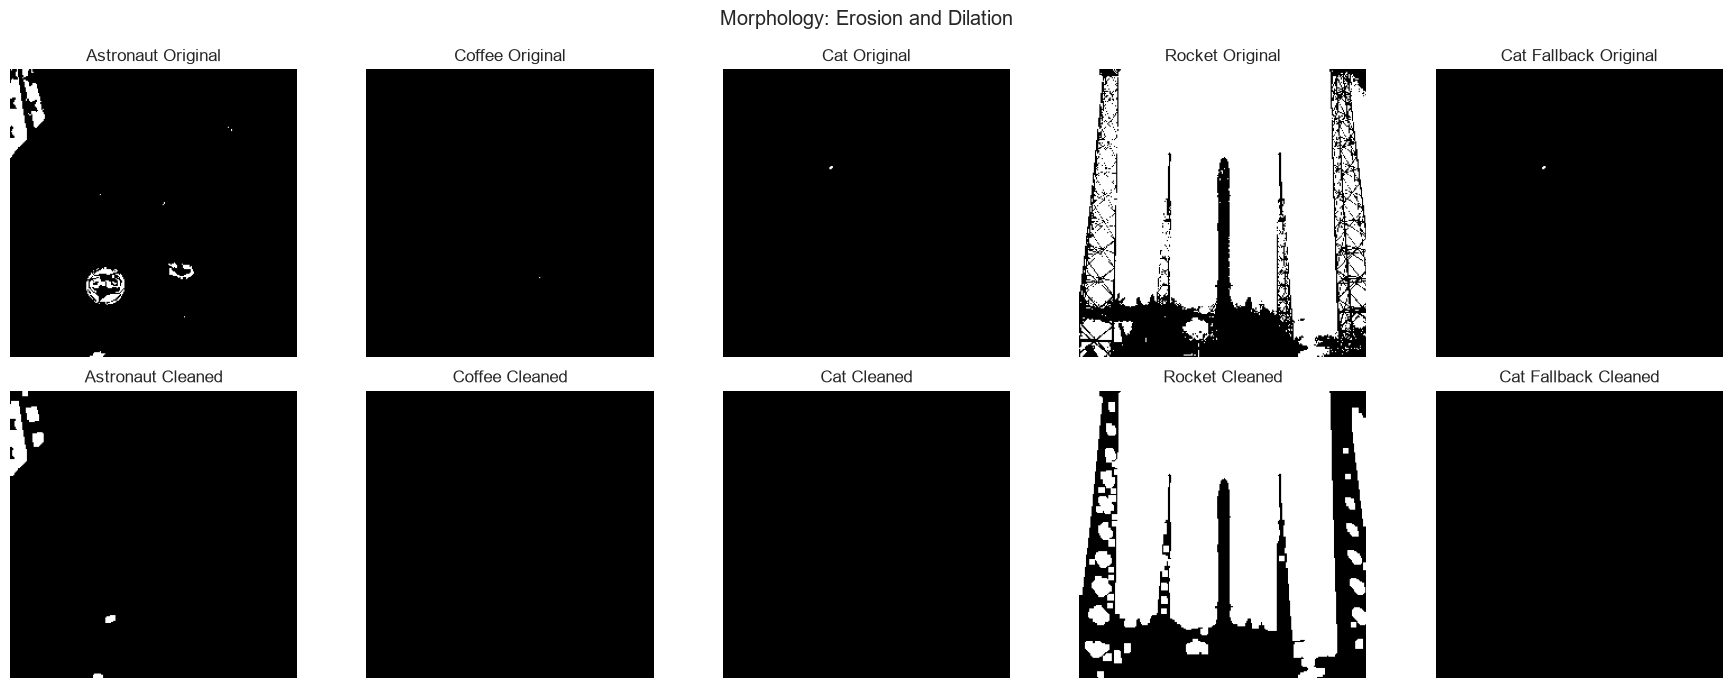

In [ ]:
kernel = np.ones((5, 5), dtype=np.uint8)

cleaned_masks = []

for mask in colour_masks:

    eroded_mask = cv2.erode(mask, kernel, iterations=1)

    cleaned_mask = cv2.dilate(eroded_mask, kernel, iterations=1)

    cleaned_masks.append(cleaned_mask)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for axis, name, mask in zip(axes[0], image_names, colour_masks):

    axis.imshow(mask, cmap="gray")
    axis.set_title(name + " Original")

    axis.axis("off")

for axis, name, mask in zip(axes[1], image_names, cleaned_masks):

    axis.imshow(mask, cmap="gray")

    axis.set_title(name + " Cleaned")

    axis.axis("off")

plt.suptitle("Morphology: Erosion and Dilation")
plt.tight_layout()
plt.show()

## Sobel edge detection
* Sobel estimates intensity changes in horizontal (x) and vertical (y) directions. We combine both gradients to create an edge map.

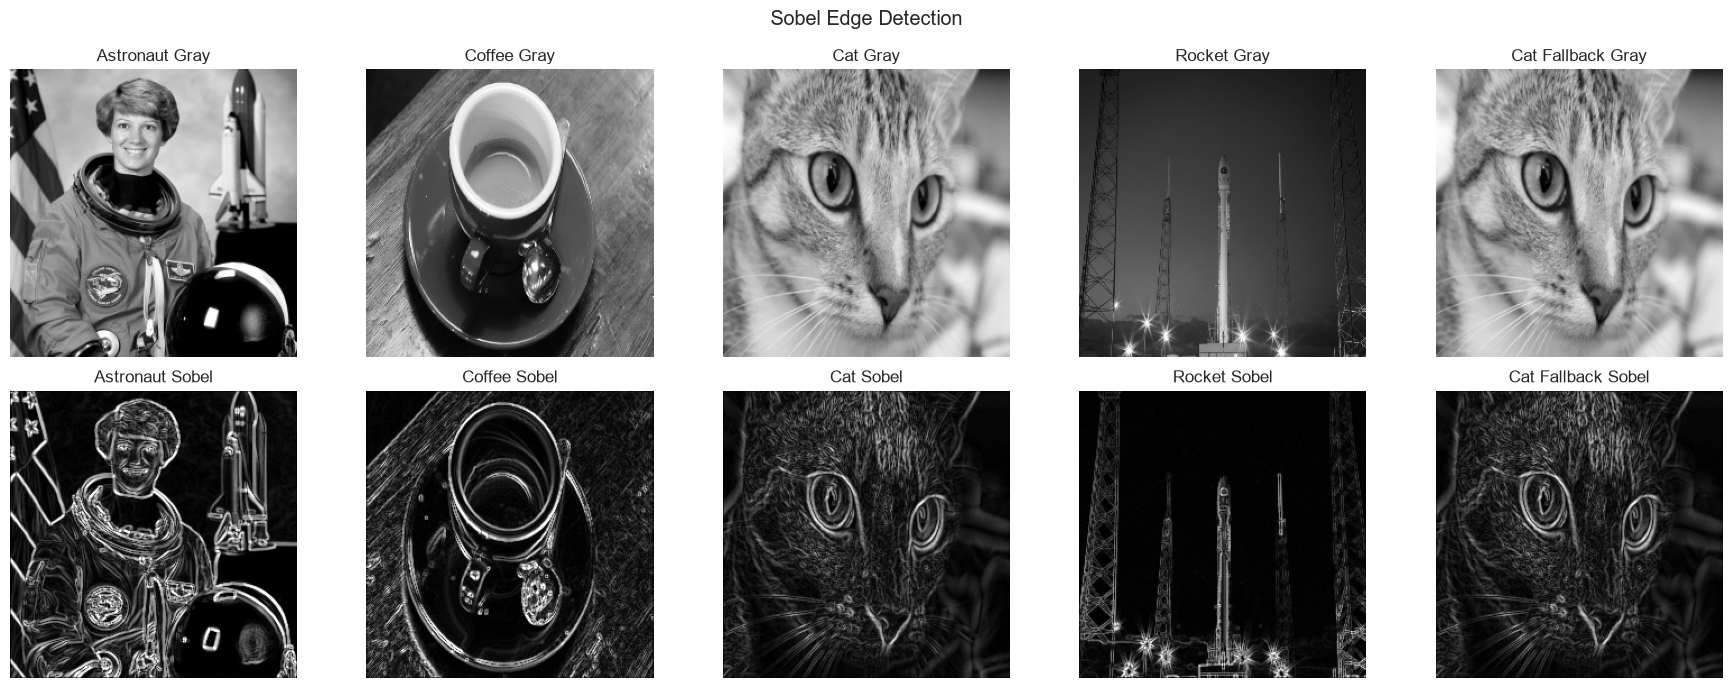

In [ ]:
gray_images = []
sobel_edges = []

for image in original_bgr_images:

    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    sobel_x = cv2.Sobel(gray_image, cv2.CV_64F, 1, 0, ksize=3)

    sobel_y = cv2.Sobel(gray_image, cv2.CV_64F, 0, 1, ksize=3)

    abs_sobel_x = cv2.convertScaleAbs(sobel_x)

    abs_sobel_y = cv2.convertScaleAbs(sobel_y)

    # Combine horizontal and vertical edges
    combined_edges = cv2.addWeighted(
        abs_sobel_x, 0.5,
        abs_sobel_y, 0.5,
        0
    )

    # Store grayscale image
    gray_images.append(gray_image)

    # Store combined edge map
    sobel_edges.append(combined_edges)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for axis, name, image in zip(axes[0], image_names, gray_images):

    axis.imshow(image, cmap="gray")
    axis.set_title(name + " Gray")
    axis.axis("off")

for axis, name, image in zip(axes[1], image_names, sobel_edges):

    axis.imshow(image, cmap="gray")
    axis.set_title(name + " Sobel")
    axis.axis("off")

plt.suptitle("Sobel Edge Detection")
plt.tight_layout()
plt.show()

# 2.3 Face Detection With Haar cascade

## load the Haar Cascade download with url
* Haar Cascade is a pre-trained face detector. It uses hand-crafted image features and does not need model training in this practical.

In [ ]:
import urllib.request

cascade_path = Path("haarcascade_frontalface_default.xml")

# OpenCV official GitHub repository to XML download file
url = "https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml"

if not cascade_path.exists():
    urllib.request.urlretrieve(url, str(cascade_path))

print("File Exists:", cascade_path.is_file())
print("File Path:", cascade_path.resolve())

File Exists: True
File Path: D:\Data\Deep Learning\DL_Practical_final\haarcascade_frontalface_default.xml


## Load Haar Cascade

In [ ]:
face_cascade = cv2.CascadeClassifier(str(cascade_path))

if face_cascade.empty():
    print("Error: Classifier load nahi hua.")
else:
    print("Haar Cascade loaded successfully!")

Haar Cascade loaded successfully!


## Detect faces in all five images

In [ ]:
face_detection_images = []
face_counts = []

for name, image in zip(image_names, original_bgr_images):

    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray_image,          
        scaleFactor=1.1,     
        minNeighbors=5,      
        minSize=(30, 30)    
    )

    # Make a copy of the original image
    result_image = image.copy()

    for (x, y, w, h) in faces:

        cv2.rectangle(
            result_image,
            (x, y),
            (x + w, y + h),
            (255, 0, 0),
            2
        )

        cv2.putText(
            result_image,
            "Face",
            (x, max(y - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )

    face_detection_images.append(result_image)
    face_counts.append(len(faces))

    print(name, "Faces Detected:", len(faces))

Astronaut Faces Detected: 1
Coffee Faces Detected: 0
Cat Faces Detected: 0
Rocket Faces Detected: 0
Cat Fallback Faces Detected: 0


## Display face detection results

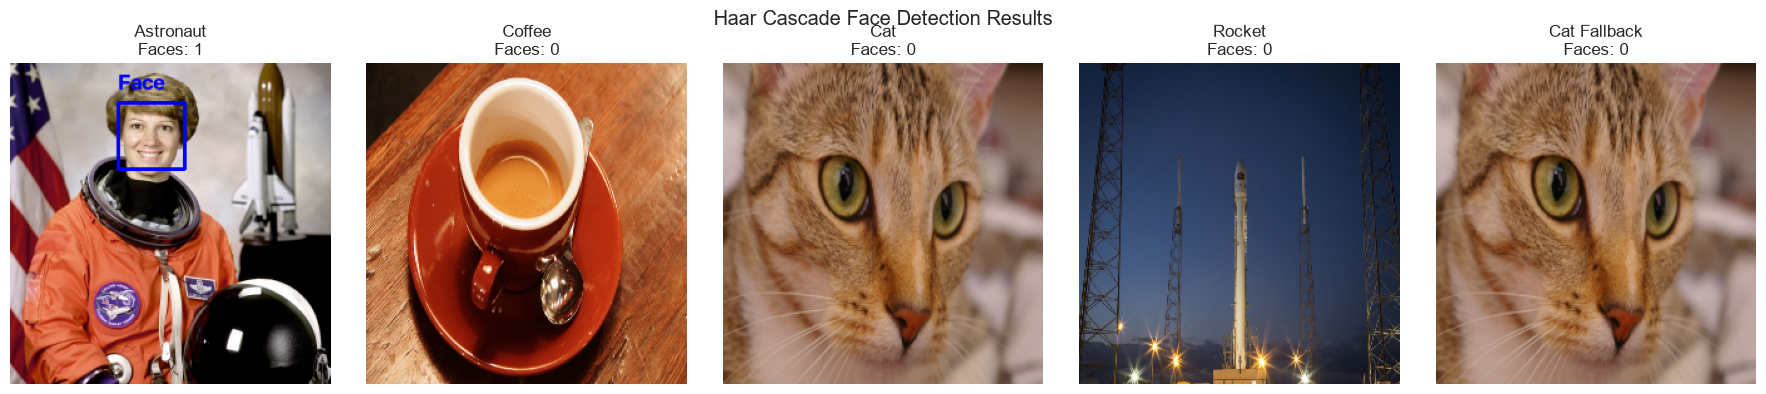

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for axis, name, image, count in zip(
    axes, image_names, face_detection_images, face_counts):

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axis.imshow(image_rgb)
    axis.set_title(f"{name}\nFaces: {count}")

    axis.axis("off")

plt.suptitle("Haar Cascade Face Detection Results")
plt.tight_layout()
plt.show()

## Compare minNeighbors values 2 and 8

In [ ]:
comparison_image = original_bgr_images[0]

comparison_gray = cv2.cvtColor(
    comparison_image,
    cv2.COLOR_BGR2GRAY
)

for neighbors in [2, 8]:

    # Detect faces with the selected setting
    detected_faces = face_cascade.detectMultiScale(
        comparison_gray,
        scaleFactor=1.1,
        minNeighbors=neighbors,
        minSize=(30, 30)
    )

    print(
        "minNeighbors =", neighbors,
        "| Faces Detected =", len(detected_faces))

minNeighbors = 2 | Faces Detected = 2
minNeighbors = 8 | Faces Detected = 1


# 2.4 Summary

## Required 5×5 summary grid

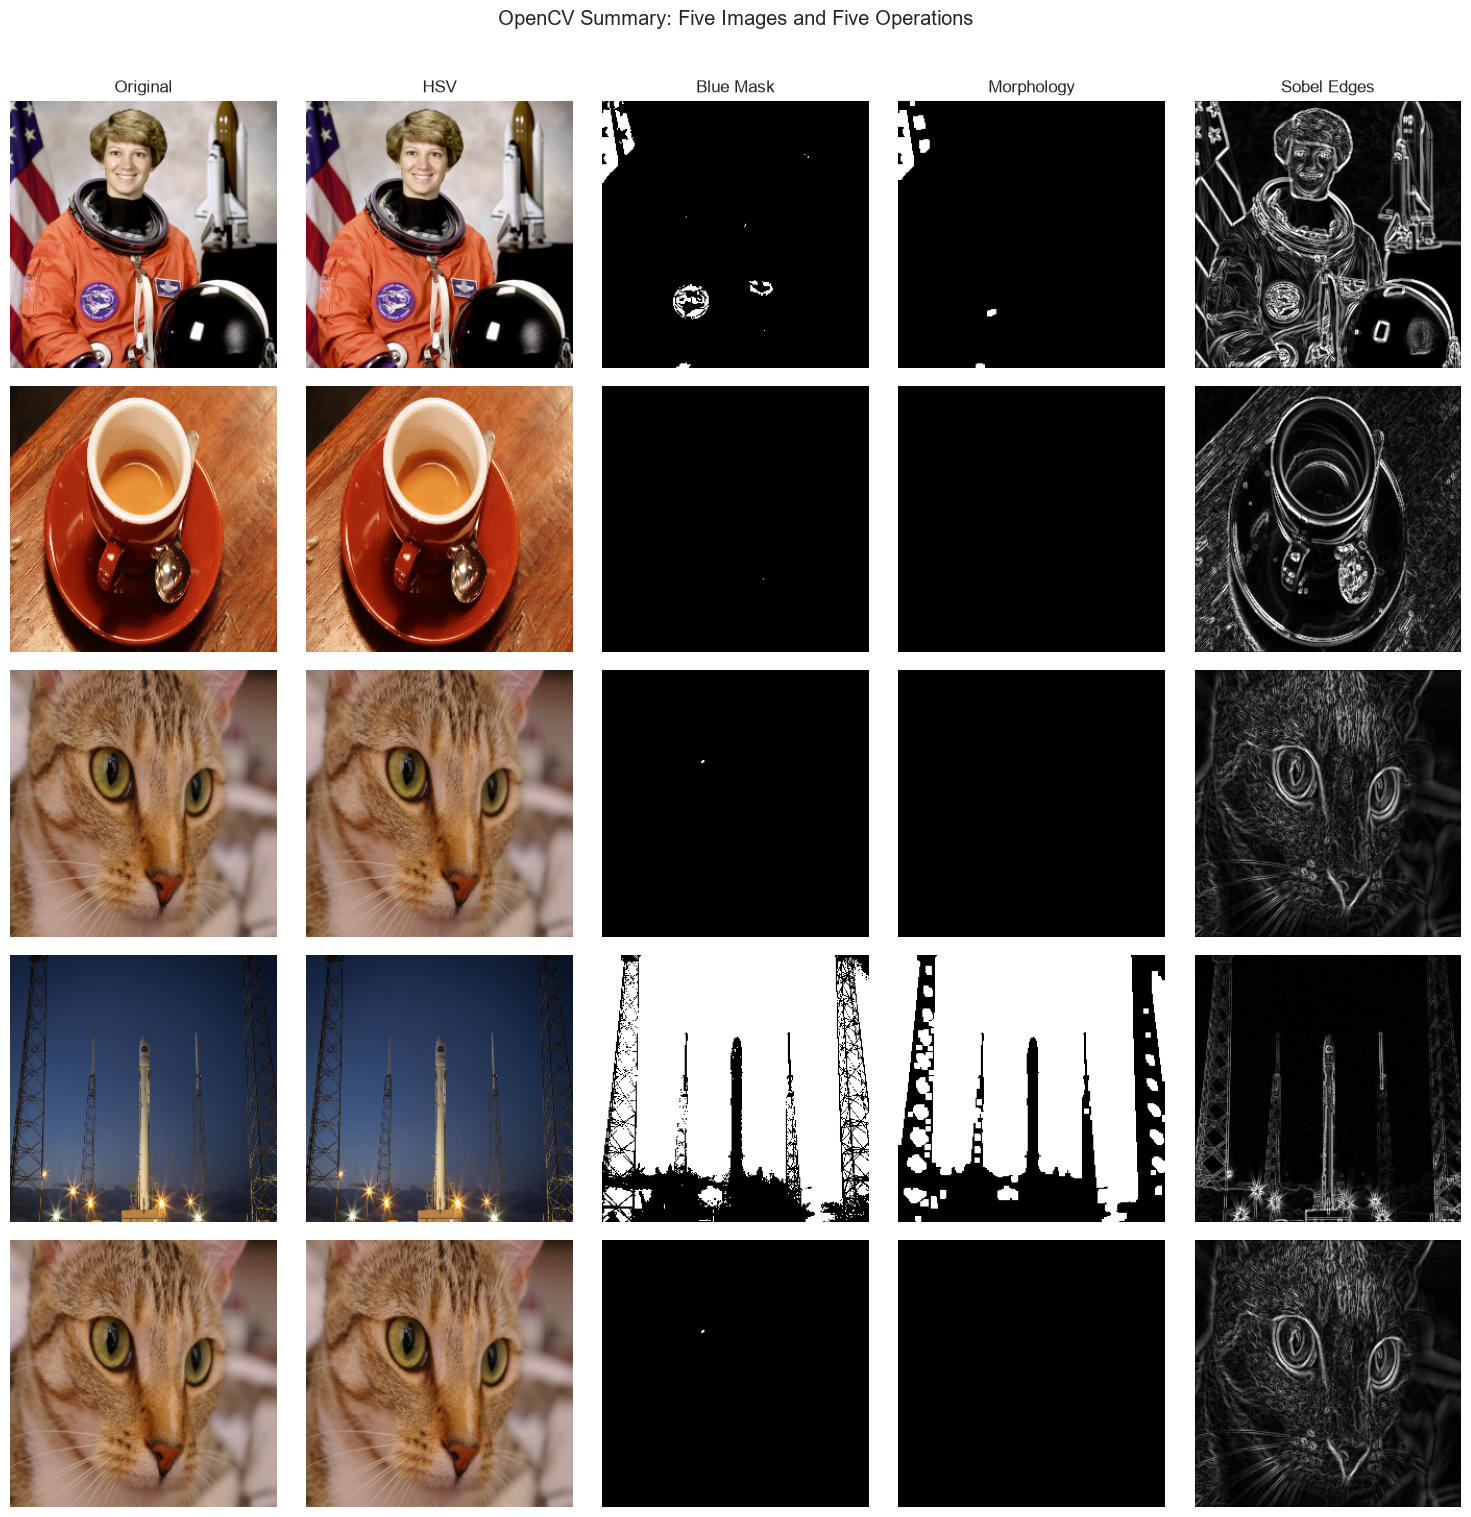

In [ ]:
fig, axes = plt.subplots(5, 5, figsize=(15, 15))

for row in range(5):

    original_rgb = cv2.cvtColor(
        original_bgr_images[row],
        cv2.COLOR_BGR2RGB )

    hsv_bgr = cv2.cvtColor(
        hsv_images[row],
        cv2.COLOR_HSV2BGR )

    hsv_rgb = cv2.cvtColor(
        hsv_bgr,
        cv2.COLOR_BGR2RGB)

    axes[row, 0].imshow(original_rgb)

    axes[row, 1].imshow(hsv_rgb)

    axes[row, 2].imshow(colour_masks[row], cmap="gray")

    axes[row, 3].imshow(cleaned_masks[row], cmap="gray")

    axes[row, 4].imshow(sobel_edges[row], cmap="gray")

    axes[row, 0].set_ylabel(image_names[row], fontsize=9)

    for column in range(5):
        axes[row, column].axis("off")

# Define the column titles
column_titles = [
    "Original",
    "HSV",
    "Blue Mask",
    "Morphology",
    "Sobel Edges"
]

for column, title in enumerate(column_titles):
    axes[0, column].set_title(title)

plt.suptitle(
    "OpenCV Summary: Five Images and Five Operations",
    y=1.0)

plt.tight_layout()
plt.show()

## save processed images 

In [ ]:
output_folder = Path("outputs")

original_folder = output_folder / "original_images"
hsv_folder = output_folder / "hsv_images"
mask_folder = output_folder / "colour_masks"
morphology_folder = output_folder / "morphology_masks"
edge_folder = output_folder / "sobel_edges"
face_folder = output_folder / "face_detections"

for folder in [
    original_folder,
    hsv_folder,
    mask_folder,
    morphology_folder,
    edge_folder,
    face_folder
]:

    folder.mkdir(parents=True, exist_ok=True)

for index, name in enumerate(image_names):

    safe_name = name.lower().replace(" ", "_").replace(":", "")

    cv2.imwrite(
        str(original_folder / f"{safe_name}_original.png"),
        original_bgr_images[index])

    hsv_bgr = cv2.cvtColor(
        hsv_images[index],
        cv2.COLOR_HSV2BGR)

    cv2.imwrite(
        str(hsv_folder / f"{safe_name}_hsv.png"),
        hsv_bgr)

    cv2.imwrite(
        str(mask_folder / f"{safe_name}_mask.png"),
        colour_masks[index])

    cv2.imwrite(
        str(morphology_folder / f"{safe_name}_morphology.png"),
        cleaned_masks[index])

    cv2.imwrite(
        str(edge_folder / f"{safe_name}_sobel.png"),
        sobel_edges[index])

    cv2.imwrite(
        str(face_folder / f"{safe_name}_faces.png"),
        face_detection_images[index])

print("Images saved successfully")
print("Output folder:", output_folder.resolve())

Images saved successfully
Output folder: D:\Data\Deep Learning\DL_Practical_final\outputs


## Face detection summary table

In [ ]:
face_summary = pd.DataFrame({
    "Image": image_names,
    "Faces Detected": face_counts
})

display(face_summary)

,Image,Faces Detected
0,Astronaut,1
1,Coffee,0
2,Cat,0
3,Rocket,0
4,Cat Fallback,0


## Final checklist

In [ ]:
print("STEP 2: OPENCV PRACTICAL CHECKLIST")

# Confirm that five images were loaded
print("1. Five images loaded:", len(image_items) == 5)

print("2. Five resized images:", len(original_bgr_images) == 5)

print("3. HSV conversion completed:", len(hsv_images) == 5)

print("4. Colour masks created:", len(colour_masks) == 5)

print("5. Morphology completed:", len(cleaned_masks) == 5)

print("6. Sobel completed:", len(sobel_edges) == 5)

print("7. Face detection completed:", len(face_detection_images) == 5)

print("8. Output folder exists:", output_folder.exists())

STEP 2: OPENCV PRACTICAL CHECKLIST
1. Five images loaded: True
2. Five resized images: True
3. HSV conversion completed: True
4. Colour masks created: True
5. Morphology completed: True
6. Sobel completed: True
7. Face detection completed: True
8. Output folder exists: True


# Written reflection answers
## Why is HSV easier than BGR for colour selection?
BGR stores blue, green, and red channel intensities. HSV separates Hue from brightness, so selecting a range of colours is often more straightforward. Lighting can still affect the mask.
## What do erosion and dilation do?
Erosion shrinks white foreground areas and may remove small white specks. Dilation expands white areas. Erosion followed by dilation is called opening and is commonly used to remove small foreground noise.
## What is Sobel edge detection?
Sobel estimates image intensity gradients in horizontal and vertical directions. Strong gradients often indicate boundaries or edges. It is a classical image-processing method, not a trained neural network.
## How does Haar Cascade work?
Haar Cascade uses hand-crafted visual features and a cascade of classifiers to find likely faces. It is lightweight, but may miss faces or produce false positives.
## How is Haar Cascade different from a CNN?
Haar Cascade relies on predefined visual features and a cascade classifier. A CNN learns image features from training data and can be more flexible, but generally requires more computation and training data.
## What happens when minNeighbors changes?
Lower values are more permissive and may create more false positives. Higher values are stricter and may miss some faces. Describe the actual counts measured in your notebook.

# Conclusion

In this practical, I used OpenCV to perform basic image processing and computer vision operations. I loaded and displayed images, resized them, converted RGB images to HSV color space, and performed blue color segmentation using masking. I also applied morphological operations such as erosion and dilation, detected edges using the Sobel operator, and detected faces using the Haar Cascade classifier. Finally, I visualized and saved the processed images and analysed face detection results under different settings.

**Result**: This practical helped me understand the fundamentals of image processing, color segmentation, edge detection, and face detection using OpenCV in Python.

# Step 3: CNN— Convolutional Neural Network

In [23]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Set seeds for more reproducible results
np.random.seed(42)
tf.random.set_seed(42)

# 3.1 Data Loading & Preparation

## Load MNIST

In [24]:
(x_train_all, y_train_all), (x_test_all, y_test_all) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 6s 1us/step


## Shapes

In [25]:
print("Full training images:", x_train_all.shape)
print("Full test images:", x_test_all.shape)

Full training images: (60000, 28, 28)
Full test images: (10000, 28, 28)


## Select 20,000 training and 4,000 test samples

In [26]:
rng = np.random.default_rng(42)

train_indexes = np.sort(rng.choice(len(x_train_all), size=20000, replace=False))

test_indexes = np.sort(rng.choice(len(x_test_all), size=4000, replace=False))

x_train, y_train = x_train_all[train_indexes], y_train_all[train_indexes]

x_test, y_test = x_test_all[test_indexes], y_test_all[test_indexes]

print("Training:", x_train.shape, y_train.shape)
print("Testing:", x_test.shape, y_test.shape)

Training: (20000, 28, 28) (20000,)
Testing: (4000, 28, 28) (4000,)


## Display sample images

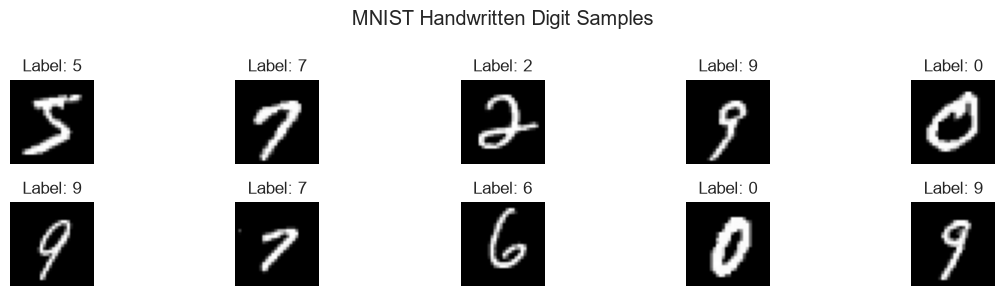

In [27]:
plt.figure(figsize=(12, 3))

for i in range(10):

    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("MNIST Handwritten Digit Samples")
plt.tight_layout()
plt.show()

## Normalize and prepare input shapes

In [28]:
# Convert training pixels to floating-point values from 0 to 1
x_train_normalized = x_train.astype("float32") / 255.0
x_test_normalized = x_test.astype("float32") / 255.0

# Flatten images for the ANN
x_train_ann = x_train_normalized.reshape(len(x_train_normalized), 784)
x_test_ann = x_test_normalized.reshape(len(x_test_normalized), 784)

x_train_cnn = np.expand_dims(x_train_normalized, axis=-1)
x_test_cnn = np.expand_dims(x_test_normalized, axis=-1)

print("ANN input:", x_train_ann.shape, x_test_ann.shape)
print("CNN input:", x_train_cnn.shape, x_test_cnn.shape)
print("Pixel range:", x_train_normalized.min(), "to", x_train_normalized.max())

ANN input: (20000, 784) (4000, 784)
CNN input: (20000, 28, 28, 1) (4000, 28, 28, 1)
Pixel range: 0.0 to 1.0


# 3.2 Build the CNN and the ANN Baseline

## Build the ANN baseline

In [29]:
ann_model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

## Compile Model

In [30]:
ann_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy", 
    metrics=["accuracy"])

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## Train the ANN

In [31]:
ann_history = ann_model.fit(
    x_train_ann,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8314 - loss: 0.6082 - val_accuracy: 0.9275 - val_loss: 0.2532
Epoch 2/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9319 - loss: 0.2395 - val_accuracy: 0.9425 - val_loss: 0.1935
Epoch 3/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9501 - loss: 0.1738 - val_accuracy: 0.9510 - val_loss: 0.1574
Epoch 4/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9615 - loss: 0.1321 - val_accuracy: 0.9580 - val_loss: 0.1361
Epoch 5/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9701 - loss: 0.1022 - val_accuracy: 0.9635 - val_loss: 0.1244
Epoch 6/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9776 - loss: 0.0803 - val_accuracy: 0.9665 - val_loss: 0.1188
Epoch 7/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9838 - loss: 0.0631 - val_accuracy: 0.9660 - val_loss: 0.1175
Epoch 8/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9883 - loss: 0.0502 - val_accuracy: 0.

## Build the CNN

In [32]:
cnn_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu", name="first_conv"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu", name="second_conv"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

## Compile Model

In [33]:
cnn_model.compile(
    optimizer="adam", 
    loss="sparse_categorical_crossentropy", 
    metrics=["accuracy"])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ first_conv (Conv2D)             │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ second_conv (Conv2D)            │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

# 3.3 Train & Evaluate

## Train the CNN with EarlyStopping

In [34]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

cnn_history = cnn_model.fit(
    x_train_cnn,
    y_train,
    epochs=15,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.8335 - loss: 0.5650 - val_accuracy: 0.9610 - val_loss: 0.1344
Epoch 2/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.9603 - loss: 0.1317 - val_accuracy: 0.9760 - val_loss: 0.0787
Epoch 3/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.9741 - loss: 0.0875 - val_accuracy: 0.9800 - val_loss: 0.0634
Epoch 4/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.9792 - loss: 0.0671 - val_accuracy: 0.9800 - val_loss: 0.0580
Epoch 5/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9828 - loss: 0.0545 - val_accuracy: 0.9825 - val_loss: 0.0506
Epoch 6/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.9865 - loss: 0.0433 - val_accuracy: 0.9850 - val_loss: 0.0473
Epoch 7/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.9894 - loss: 0.0352 - val_accuracy: 0.9845 - val_loss: 0.0460
Epoch 8/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9914 - loss: 0.0294 - val_accu

## Plot accuracy curves

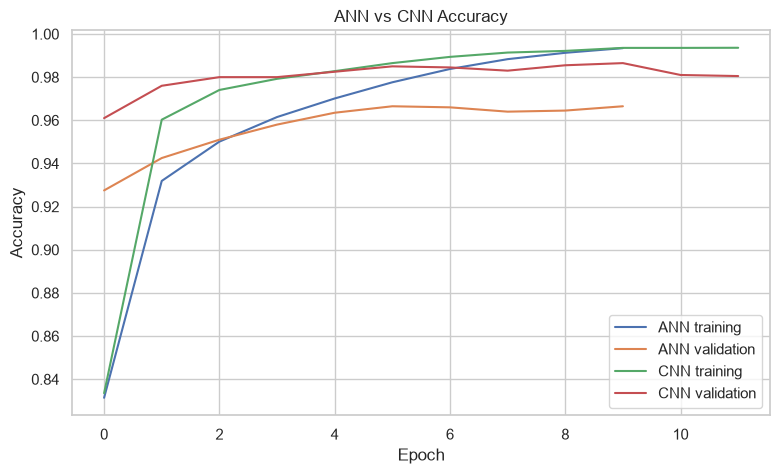

In [36]:
plt.figure(figsize=(9, 5))

plt.plot(ann_history.history["accuracy"], label="ANN training")
plt.plot(ann_history.history["val_accuracy"], label="ANN validation")
plt.plot(cnn_history.history["accuracy"], label="CNN training")
plt.plot(cnn_history.history["val_accuracy"], label="CNN validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN vs CNN Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## Plot Loss Curves

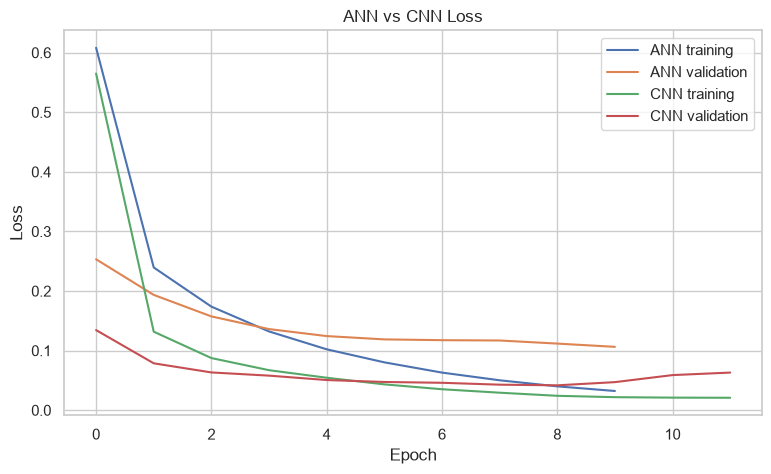

In [37]:
plt.figure(figsize=(9, 5))

plt.plot(ann_history.history["loss"], label="ANN training")
plt.plot(ann_history.history["val_loss"], label="ANN validation")
plt.plot(cnn_history.history["loss"], label="CNN training")
plt.plot(cnn_history.history["val_loss"], label="CNN validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN vs CNN Loss")
plt.legend()
plt.grid(True)
plt.show()

## Evaluate both models on the same test image

In [38]:
ann_test_loss, ann_test_accuracy = ann_model.evaluate(x_test_ann, y_test, verbose=0)
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(x_test_cnn, y_test, verbose=0)
ann_probabilities = ann_model.predict(x_test_ann, verbose=0)

ann_predictions = np.argmax(ann_probabilities, axis=1)

cnn_probabilities = cnn_model.predict(x_test_cnn, verbose=0)
cnn_predictions = np.argmax(cnn_probabilities, axis=1)

print(f"ANN test accuracy: {ann_test_accuracy:.4f}")
print(f"CNN test accuracy: {cnn_test_accuracy:.4f}")

ANN test accuracy: 0.9630
CNN test accuracy: 0.9833


## Create the ANN-versus-CNN table

In [39]:
results_df = pd.DataFrame({
    "Model": ["ANN", "CNN"],
    "Test Accuracy": [ann_test_accuracy, cnn_test_accuracy],
    "Test Loss": [ann_test_loss, cnn_test_loss]
})

display(results_df)

,Model,Test Accuracy,Test Loss
0,ANN,0.96300,0.134715
1,CNN,0.98325,0.053808


## CNN classification report

In [ ]:
print(classification_report(
    y_test, 
    cnn_predictions, 
    digits=4, zero_division=0))

              precision    recall  f1-score   support

           0     0.9678    0.9974    0.9824       392
           1     0.9807    0.9951    0.9879       409
           2     0.9921    0.9691    0.9804       388
           3     0.9865    0.9887    0.9876       443
           4     0.9780    0.9950    0.9865       403
           5     0.9804    0.9804    0.9804       357
           6     0.9949    0.9800    0.9874       400
           7     0.9639    0.9907    0.9771       431
           8     0.9975    0.9682    0.9826       409
           9     0.9944    0.9647    0.9793       368

    accuracy                         0.9832      4000
   macro avg     0.9836    0.9829    0.9832      4000
weighted avg     0.9835    0.9832    0.9832      4000



## CNN confusion matrix

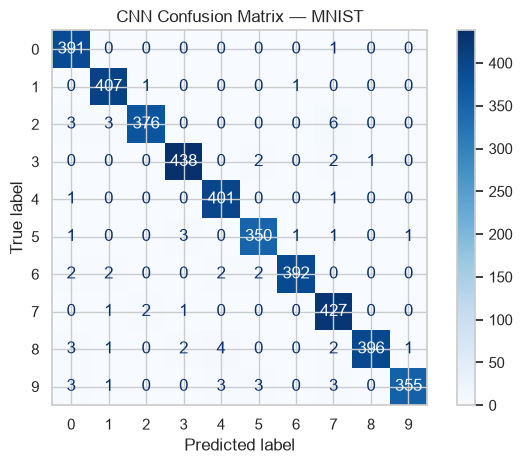

In [41]:
cnn_cm = confusion_matrix(y_test, cnn_predictions, labels=np.arange(10))

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cnn_cm, 
    display_labels=np.arange(10))

cm_display.plot(cmap="Blues", values_format="d")
plt.title("CNN Confusion Matrix — MNIST")
plt.tight_layout()
plt.show()

## Visualize first-layer feature maps

Feature maps shape: (1, 26, 26, 32)


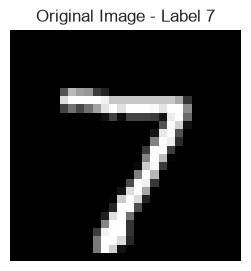

In [ ]:
feature_input = keras.Input(shape=(28, 28, 1))

x = feature_input

for layer in cnn_model.layers:
    x = layer(x)

    if layer.name == "first_conv":
        feature_output = x
        break

feature_map_model = keras.Model(
    inputs=feature_input,
    outputs=feature_output
)

sample_image = x_test_cnn[0:1]
feature_maps = feature_map_model.predict(
                        sample_image, verbose=0)

print("Feature maps shape:", feature_maps.shape)

plt.figure(figsize=(3, 3))
plt.imshow(sample_image[0, :, :, 0], cmap="gray")
plt.title(f"Original Image - Label {y_test[0]}")
plt.axis("off")
plt.show()

## Display the first 8 feature maps

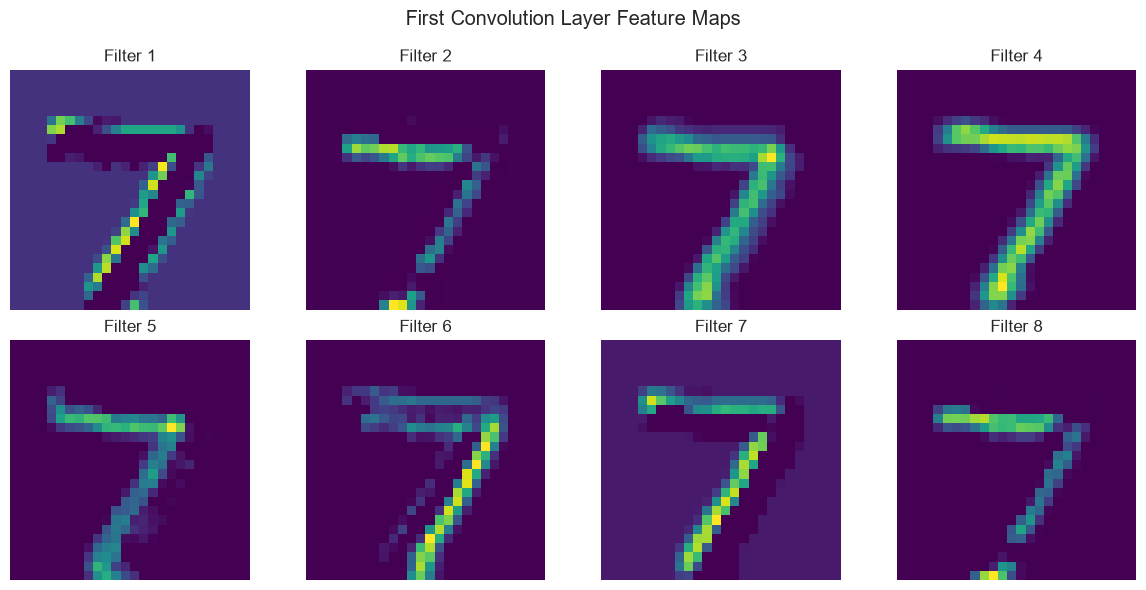

In [45]:
plt.figure(figsize=(12, 6))

for i in range(8):

    plt.subplot(2, 4, i + 1)

    plt.imshow(feature_maps[0, :, :, i], cmap="viridis")

    plt.title(f"Filter {i + 1}")

    plt.axis("off")

plt.suptitle("First Convolution Layer Feature Maps")
plt.tight_layout()
plt.show()

## Display incorrectly predicted images

Incorrect predictions: 67


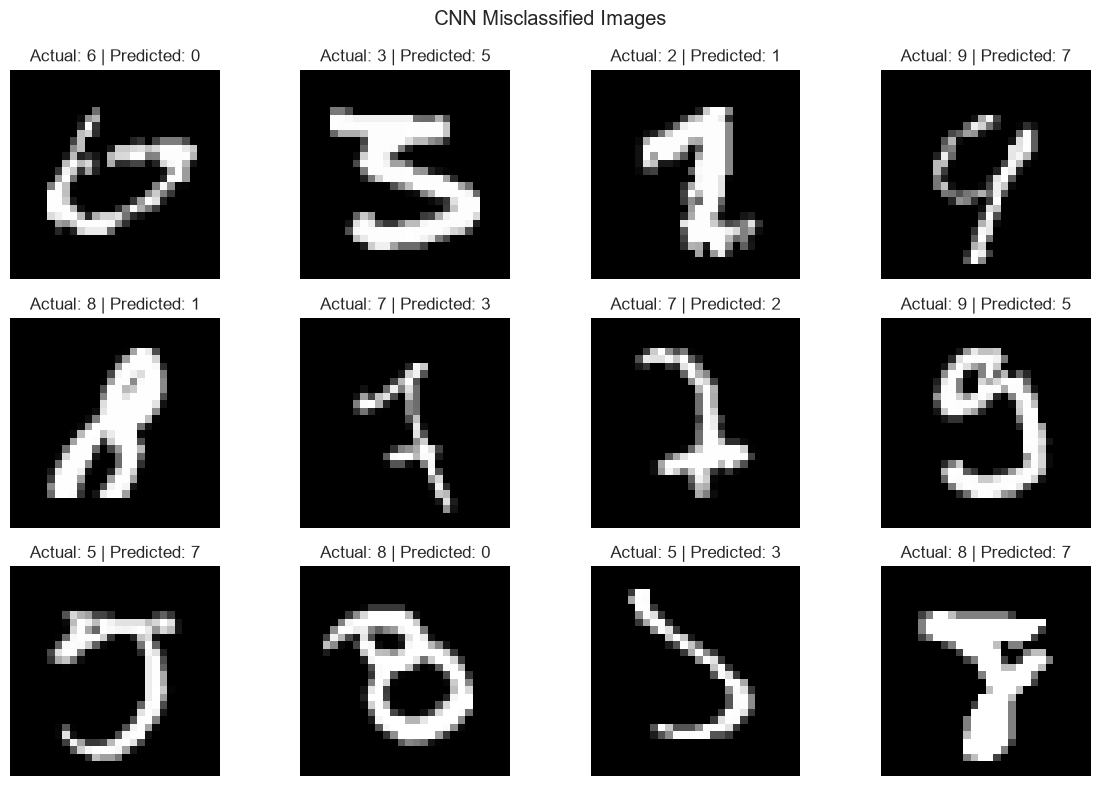

In [46]:
wrong_indexes = np.where(cnn_predictions != y_test)[0]
print("Incorrect predictions:", len(wrong_indexes))

number_to_show = min(12, len(wrong_indexes))

if number_to_show > 0:

    plt.figure(figsize=(12, 8))

    for position in range(number_to_show):
        image_index = wrong_indexes[position]

        plt.subplot(3, 4, position + 1)
        plt.imshow(x_test[image_index], cmap="gray")
        plt.title(f"Actual: {y_test[image_index]} | Predicted: {cnn_predictions[image_index]}")
        plt.axis("off")

    plt.suptitle("CNN Misclassified Images")
    plt.tight_layout()
    plt.show()
else:
    print("No incorrect predictions found in this test subset.")

# 3.4 Save & Reflect

## Save the CNN model

In [47]:
cnn_model.save("cnn_mnist_model.h5")

print("Saved model: cnn_mnist_model.h5")

Saved model: cnn_mnist_model.h5


## Load the saved model and test one image

In [48]:
loaded_cnn_model = keras.models.load_model("cnn_mnist_model.h5")

one_image = x_test_cnn[0:1]
one_probabilities = loaded_cnn_model.predict(one_image, verbose=0)
predicted_digit = int(np.argmax(one_probabilities, axis=1)[0])

print("Actual digit:", int(y_test[0]))
print("Predicted digit:", predicted_digit)

Actual digit: 7
Predicted digit: 7


# Reflection: CNN on MNIST

**1. What do the feature maps show you?**

Feature maps show the patterns detected by convolution filters in an image. Early filters may respond to edges, curves, and strokes that help the CNN recognize handwritten digits.

**2. Which model has fewer parameters and why?**

The number of parameters depends on the model architecture. In our implementation, the ANN and CNN parameter counts are printed in the comparison cell. The ANN may have fewer parameters in this particular design because the CNN's flattened feature maps feed into a dense layer. Convolution layers use shared filters, which helps reuse weights across an image.

**3. What does MaxPooling do?**

MaxPooling reduces the width and height of feature maps by selecting the maximum value from each local region. It reduces computation and helps the network focus on important features.

**4. Which digits did the CNN confuse and why might that be?**

The confused digits can be identified from the off-diagonal entries of the confusion matrix. Digits with similar shapes or writing styles may be misclassified because their strokes, curves, or loops can look alike. The specific confused digits should be reported from the actual results of this experiment.


# Conclusion
The ANN and CNN were trained and evaluated on the same selected MNIST samples. Pixel values were normalized to 0–1. The ANN treated each image as a flat vector, while the CNN learned spatial patterns using convolution and pooling. Training curves, the results table, classification report, confusion matrix, feature maps, and incorrectly predicted images help compare the models. EarlyStopping was used during CNN training, and the model was saved as cnn_mnist_model.h5.

Report the accuracy produced by your own notebook run. Do not assume a fixed accuracy in advance

# Step 4: RNN — Recurrent Neural Network

In [49]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay

# Set random seeds for more reproducible results
np.random.seed(42)
tf.random.set_seed(42)


## Set model settings

In [50]:
VOCAB_SIZE = 10000

MAX_LEN = 200

BATCH_SIZE = 64

EPOCHS = 10

print("Vocabulary:", VOCAB_SIZE, "Maximum length:", MAX_LEN)

Vocabulary: 10000 Maximum length: 200


# 4.1  Data Loading & Preparation

## Load the IMDB dataset

In [51]:
(x_train_raw, y_train), (x_test_raw, y_test) = keras.datasets.imdb.load_data(num_words=VOCAB_SIZE)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 41s 2us/step


## Shapes of review

In [52]:
print("Training reviews:", len(x_train_raw), "Labels:", y_train.shape)
print("Test reviews:", len(x_test_raw), "Labels:", y_test.shape)

print("First review sequence:", x_train_raw[0][:20])
print("First review label (0=negative, 1=positive):", y_train[0])

Training reviews: 25000 Labels: (25000,)
Test reviews: 25000 Labels: (25000,)
First review sequence: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
First review label (0=negative, 1=positive): 1


## Explore labels and review lengths

In [56]:
label_counts = pd.Series(y_train).value_counts().sort_index()
print("Label counts (0=negative, 1=positive):")
print(label_counts)

Label counts (0=negative, 1=positive):
0    12500
1    12500
Name: count, dtype: int64


## Plot the sentiment distribution

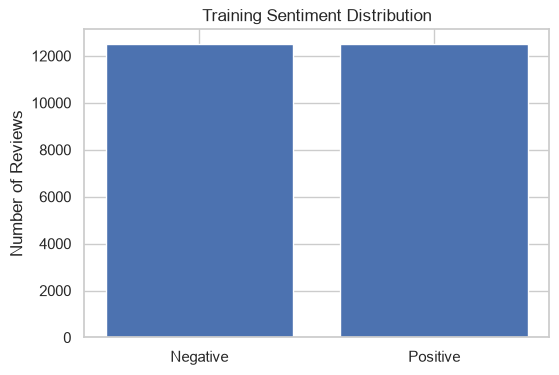

In [57]:
plt.figure(figsize=(6, 4))
plt.bar(["Negative", "Positive"], [label_counts.get(0, 0), label_counts.get(1, 0)])
plt.title("Training Sentiment Distribution")
plt.ylabel("Number of Reviews")
plt.show()

## Statistics review-length

In [54]:
review_lengths = [len(review) for review in x_train_raw]

print("Shortest:", min(review_lengths))
print("Median:", int(np.median(review_lengths)))
print("95th percentile:", int(np.percentile(review_lengths, 95)))
print("Longest:", max(review_lengths))

Shortest: 11
Median: 178
95th percentile: 610
Longest: 2494


##  Plot the review-length distribution

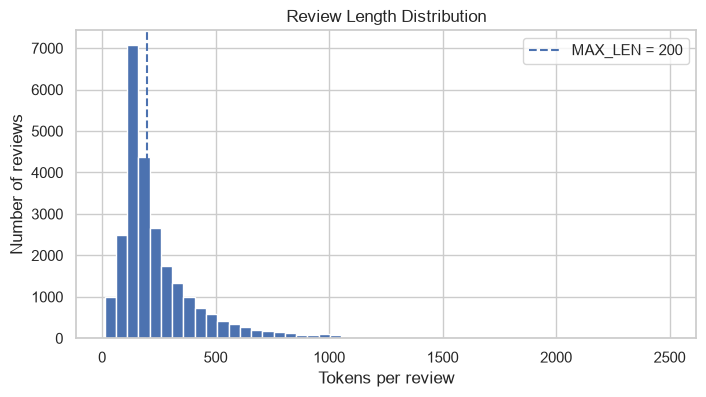

In [55]:
plt.figure(figsize=(8, 4))
plt.hist(review_lengths, bins=50)
plt.axvline(MAX_LEN, linestyle="--", label="MAX_LEN = 200")
plt.xlabel("Tokens per review")
plt.ylabel("Number of reviews")
plt.title("Review Length Distribution")
plt.legend()
plt.show()

## Pad the sequences

In [58]:
x_train = keras.utils.pad_sequences(x_train_raw, maxlen=MAX_LEN, padding="pre", truncating="pre")
x_test = keras.utils.pad_sequences(x_test_raw, maxlen=MAX_LEN, padding="pre", truncating="pre")

print("Training input shape:", x_train.shape)
print("Test input shape:", x_test.shape)

Training input shape: (25000, 200)
Test input shape: (25000, 200)


# 4.2  Build the RNN and a Baseline

## Build the SimpleRNN model

In [59]:
rnn_model = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=32, mask_zero=True),
    layers.SimpleRNN(64),
    layers.Dense(1, activation="sigmoid")
])

## Compile Model

In [60]:
rnn_model.compile(
    optimizer="adam", 
    loss="binary_crossentropy", 
    metrics=["accuracy", keras.metrics.AUC(name="auc")]
)
rnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

## Train the RNN with EarlyStopping

In [61]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

rnn_history = rnn_model.fit(
    x_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.6761 - auc: 0.7561 - loss: 0.5827 - val_accuracy: 0.7944 - val_auc: 0.8719 - val_loss: 0.4513
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 20s 30ms/step - accuracy: 0.7136 - auc: 0.7829 - loss: 0.5667 - val_accuracy: 0.7388 - val_auc: 0.8311 - val_loss: 0.5805
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 26s 74ms/step - accuracy: 0.8090 - auc: 0.8941 - loss: 0.4127 - val_accuracy: 0.8148 - val_auc: 0.8790 - val_loss: 0.4561


## Plot RNN accuracy

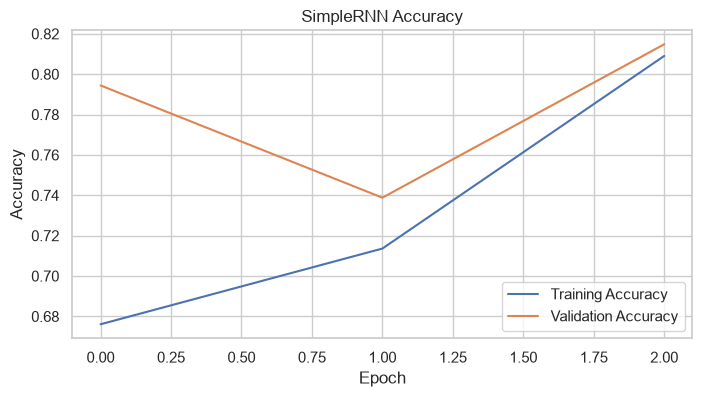

In [62]:
plt.figure(figsize=(8, 4))
plt.plot(rnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(rnn_history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("SimpleRNN Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## Plot RNN Loss

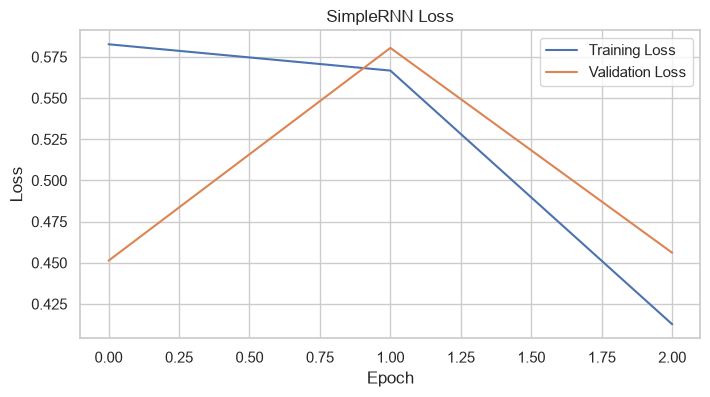

In [63]:
plt.figure(figsize=(8, 4))
plt.plot(rnn_history.history["loss"], label="Training Loss")
plt.plot(rnn_history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("SimpleRNN Loss")
plt.legend()
plt.grid(True)
plt.show()

# 4.3  Train & Evaluate

## Evaluate on test data

In [65]:
test_loss, test_accuracy, test_auc = rnn_model.evaluate(x_test, y_test, verbose=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test ROC-AUC: {test_auc:.4f}")

y_probability = rnn_model.predict(x_test, verbose=0).ravel()

y_prediction = (y_probability >= 0.5).astype(int)

Test loss: 0.4472
Test accuracy: 0.7984
Test ROC-AUC: 0.8748


## Classification Report

In [66]:
print(classification_report(
       y_test, 
       y_prediction, 
       target_names=["Negative", "Positive"], 
       digits=4, zero_division=0)
    )

              precision    recall  f1-score   support

    Negative     0.7911    0.8109    0.8009     12500
    Positive     0.8060    0.7859    0.7959     12500

    accuracy                         0.7984     25000
   macro avg     0.7986    0.7984    0.7984     25000
weighted avg     0.7986    0.7984    0.7984     25000



## Confusion matrix

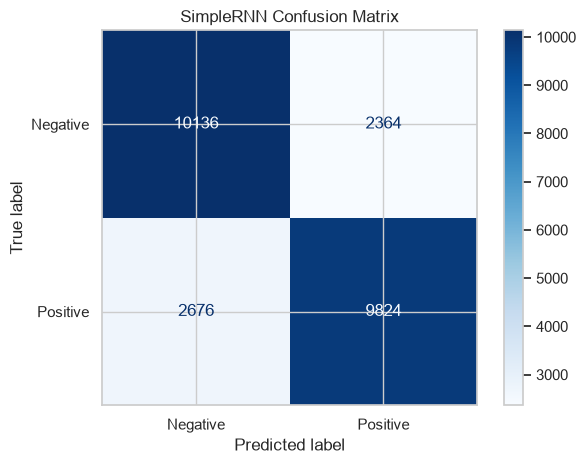

In [ ]:
cm = confusion_matrix(y_test, y_prediction, labels=[0, 1])

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm, 
    display_labels=["Negative", "Positive"])

cm_display.plot(cmap="Blues", values_format="d")
plt.title("SimpleRNN Confusion Matrix")
plt.tight_layout()
plt.show()

## ROC curve

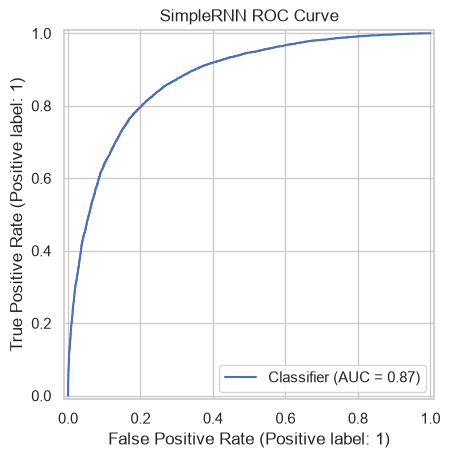

In [68]:
RocCurveDisplay.from_predictions(
    y_test, 
    y_probability)

plt.title("SimpleRNN ROC Curve")
plt.grid(True)
plt.show()

## Predict sample reviews

In [69]:
word_index = keras.datasets.imdb.get_word_index()
word_index = {word: index + 3 for word, index in word_index.items()}
word_index["<PAD>"] = 0
word_index["<START>"] = 1
word_index["<UNK>"] = 2
word_index["<UNUSED>"] = 3

sample_reviews = ["this movie was great and enjoyable", "this movie was boring and bad"]
sample_sequences = []

for review in sample_reviews:

    words = review.lower().split()
    sequence = [1]

    for word in words:
        sequence.append(word_index.get(word, 2))
    sequence = [index if index < VOCAB_SIZE else 2 for index in sequence]
    sample_sequences.append(sequence)

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 3s 2us/step


## Pad the sample reviews to MAX_LEN

In [70]:
sample_padded = keras.utils.pad_sequences(
        sample_sequences, 
        maxlen=MAX_LEN, 
        padding="pre", 
        truncating="pre")

sample_probabilities = rnn_model.predict(sample_padded, verbose=0).ravel()

for review, probability in zip(sample_reviews, sample_probabilities):
    sentiment = "Positive" if probability >= 0.5 else "Negative"
    print("Review:", review)
    print(f"Positive probability: {probability:.4f}")
    print("Predicted sentiment:", sentiment)
    print("-" * 35)

Review: this movie was great and enjoyable
Positive probability: 0.8184
Predicted sentiment: Positive
-----------------------------------
Review: this movie was boring and bad
Positive probability: 0.0830
Predicted sentiment: Negative
-----------------------------------


# 4.4  Save & Reflect

## Save and reload the model

In [71]:
rnn_model.save("rnn_imdb_sentiment_model.keras")

print("Saved model: rnn_imdb_sentiment_model.keras")

Saved model: rnn_imdb_sentiment_model.keras


### Load the saved model

In [72]:
loaded_rnn_model = keras.models.load_model("rnn_imdb_sentiment_model.keras")

loaded_loss, loaded_accuracy, loaded_auc = loaded_rnn_model.evaluate(x_test, y_test, verbose=0)

print(f"Loaded model test accuracy: {loaded_accuracy:.4f}")
print(f"Loaded model test ROC-AUC: {loaded_auc:.4f}")

Loaded model test accuracy: 0.7984
Loaded model test ROC-AUC: 0.8748


# RNN Temperature Prediction

**1. How does a GRU differ from a SimpleRNN? What do its gates do?**

A SimpleRNN passes information from one time step to the next using a hidden state. It can have difficulty learning long-term dependencies. A GRU (Gated Recurrent Unit) uses gates to control information flow. The **update gate** decides how much previous information to keep, while the **reset gate** controls how much past information to use when creating new information. These gates help a GRU learn longer-term patterns.

**2. Why did we fit the scaler on the training data only?**

We fit the scaler only on the training data to prevent data leakage. The scaler learns values such as the mean and standard deviation from the training set. We then use that same fitted scaler to transform the validation and test data. This ensures that information from unseen data does not influence training.

**3. Did the model beat the naive baseline?**

The model beats the naive baseline if its test RMSE or MAE is lower than the corresponding baseline error. A naive temperature forecasting baseline might predict that the next temperature will equal the most recently observed temperature. Compare both methods on the same test samples before deciding whether the RNN performs better.

**4. What do RMSE and MAE mean in °C?**

- **MAE (Mean Absolute Error):** The average absolute difference between predicted and actual temperatures. For example, an MAE of 1.5°C means predictions differ from actual temperatures by an average absolute amount of 1.5°C.
- **RMSE (Root Mean Squared Error):** The square root of the average squared prediction errors. It is expressed in °C and penalizes larger errors more strongly than MAE.

Lower RMSE and MAE indicate better predictions. Report the actual test metrics from your experiment.


# Conclusion
The SimpleRNN model was trained to classify IMDB movie reviews as negative or positive. Reviews were represented as word-index sequences and padded to a fixed length. The Embedding layer learned word vectors, and SimpleRNN processed each sequence before the sigmoid output predicted sentiment. Training curves, test metrics, a classification report, confusion matrix, and ROC curve were used to evaluate the model. EarlyStopping monitored validation loss, and the trained model was saved as rnn_imdb_sentiment_model.keras.

Use the actual metrics from your notebook run in your practical report.

# Step 5: Transformers — Fill-Mask, Question Answering & Text Generation

In [83]:
from tensorflow.keras.layers import MultiHeadAttention
from tensorflow.keras.layers import Dense, LayerNormalization
from tensorflow.keras.layers import Dropout

In [73]:
# Set seeds for more reproducible results
np.random.seed(42)
tf.random.set_seed(42)

## Set Model Setting

In [74]:
VOCAB_SIZE = 10000

MAX_LEN = 200

TRAIN_SAMPLES = 10000

TEST_SAMPLES = 3000

EPOCHS = 5

BATCH_SIZE = 64

print("Vocabulary:", VOCAB_SIZE, "Sequence length:", MAX_LEN)
print("Training samples:", TRAIN_SAMPLES, "Test samples:", TEST_SAMPLES)

Vocabulary: 10000 Sequence length: 200
Training samples: 10000 Test samples: 3000


## Load and inspect IMDB

In [75]:
(x_train_all, y_train_all), (x_test_all, y_test_all) = keras.datasets.imdb.load_data(num_words=VOCAB_SIZE)

## Train & Test Subset Reviews

In [ ]:
x_train_raw = x_train_all[:TRAIN_SAMPLES]
y_train = y_train_all[:TRAIN_SAMPLES]

x_test_raw = x_test_all[:TEST_SAMPLES]
y_test = y_test_all[:TEST_SAMPLES]

print("Training reviews:", len(x_train_raw))
print("Test reviews:", len(x_test_raw))

Training reviews: 10000
Test reviews: 3000


## Count Labels

In [77]:
label_counts = pd.Series(y_train).value_counts().sort_index()

print("Labels (0=negative, 1=positive):")
print(label_counts)

Labels (0=negative, 1=positive):
0    4947
1    5053
Name: count, dtype: int64


## Plot sentiment label counts

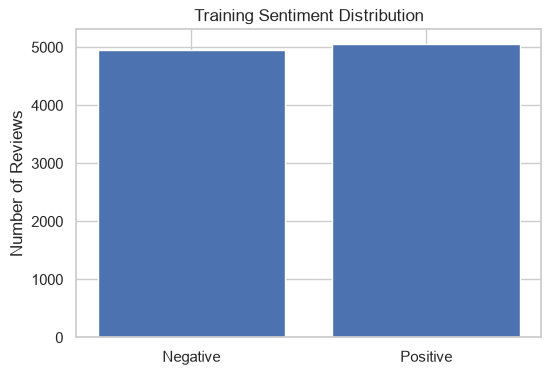

In [78]:
plt.figure(figsize=(6, 4))
plt.bar(["Negative", "Positive"], [label_counts.get(0, 0), label_counts.get(1, 0)])
plt.title("Training Sentiment Distribution")
plt.ylabel("Number of Reviews")
plt.show()

## Calculate review lengths Statistics

In [79]:
review_lengths = [len(review) for review in x_train_raw]

print("Median review length:", int(np.median(review_lengths)))
print("95th percentile:", int(np.percentile(review_lengths, 95)))

Median review length: 178
95th percentile: 610


## Plot review lengths

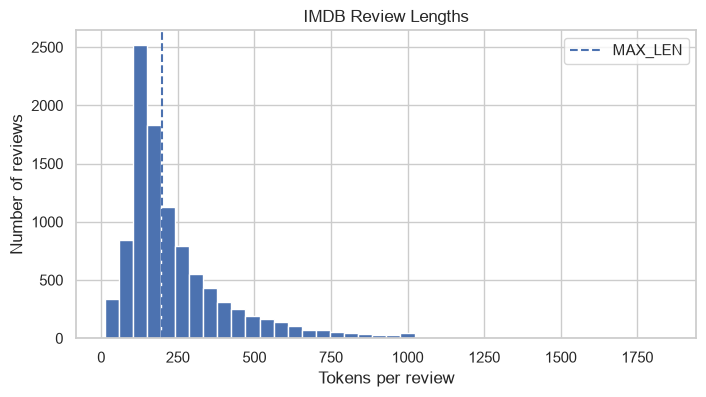

In [80]:
plt.figure(figsize=(8, 4))
plt.hist(review_lengths, bins=40)
plt.axvline(MAX_LEN, linestyle="--", label="MAX_LEN")
plt.xlabel("Tokens per review")
plt.ylabel("Number of reviews")
plt.title("IMDB Review Lengths")
plt.legend()
plt.show()

## Pad the reviews

In [81]:
x_train = keras.utils.pad_sequences(x_train_raw, maxlen=MAX_LEN, padding="pre", truncating="pre")
x_test = keras.utils.pad_sequences(x_test_raw, maxlen=MAX_LEN, padding="pre", truncating="pre")

print("Training input shape:", x_train.shape)
print("Test input shape:", x_test.shape)

Training input shape: (10000, 200)
Test input shape: (3000, 200)


## Create token and positional embeddings

In [82]:
class TokenAndPositionEmbedding(layers.Layer):
    def __init__(self, max_length, vocabulary_size, embedding_dim):

        super().__init__()
        self.token_embedding = layers.Embedding(vocabulary_size, embedding_dim, mask_zero=True)
        self.position_embedding = layers.Embedding(max_length, embedding_dim)

    # Define how the layer processes token indexes
    def call(self, token_ids):
        sequence_length = tf.shape(token_ids)[-1]
        positions = tf.range(start=0, limit=sequence_length, delta=1)
        token_vectors = self.token_embedding(token_ids)
        position_vectors = self.position_embedding(positions)
        return token_vectors + position_vectors

## Create a Transformer Encoder block

In [84]:
embedding_dim = 32
num_heads = 2
ff_dim = 64

def transformer_encoder(inputs):

    attention_output = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embedding_dim // num_heads
    )(inputs, inputs)

    attention_output = tf.keras.layers.Add()(
        [inputs, attention_output]
    )

    attention_output = LayerNormalization()(attention_output)

    ff_output = Dense(ff_dim, activation="relu")(attention_output)

    ff_output = Dense(embedding_dim)(ff_output)

    output = tf.keras.layers.Add()(
        [attention_output, ff_output]
    )

    output = LayerNormalization()(output)

    return output

## Test the Transformer Encoder

In [86]:
sample_input = tf.random.normal((1, 10, embedding_dim))

sample_output = transformer_encoder(sample_input)

print("Input shape:", sample_input.shape)
print("Output shape:", sample_output.shape)

Input shape: (1, 10, 32)
Output shape: (1, 10, 32)


## Build the Transformer sentiment model

In [90]:
MAX_LEN = 200
VOCAB_SIZE = 10000
EMBEDDING_DIM = 32
NUMBER_OF_HEADS = 2
FEED_FORWARD_DIM = 64

input_tokens = keras.Input(shape=(MAX_LEN,), dtype="int32")

embedded_tokens = TokenAndPositionEmbedding(
    MAX_LEN, VOCAB_SIZE, EMBEDDING_DIM
)(input_tokens)

encoded_tokens = transformer_encoder(embedded_tokens)

pooled_tokens = layers.GlobalAveragePooling1D()(encoded_tokens)
pooled_tokens = layers.Dropout(0.2)(pooled_tokens)

output_sentiment = layers.Dense(
    1, activation="sigmoid"
    )(pooled_tokens)

transformer_model = keras.Model(
    inputs=input_tokens,
    outputs=output_sentiment
)

transformer_model.summary()

Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7       │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_and_position… │ (None, 200, 32)   │    326,400 │ input_layer_7[0]… │
│ (TokenAndPositionE… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 200, 32)   │      4,224 │ token_and_positi… │
│ (MultiHeadAttentio… │                   │            │ token_and_positi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 200, 32)   │          0 │ token_and_positi… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 200, 32)   │         64 │ add_6[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 200, 64)   │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 200, 32)   │      2,080 │ dense_13[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_7 (Add)         │ (None, 200, 32)   │          0 │ layer_normalizat… │
│                     │                   │            │ dense_14[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 200, 32)   │         64 │ add_7[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 32)        │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 1)         │         33 │ dropout_5[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 334,977 (1.28 MB)

 Trainable params: 334,977 (1.28 MB)

 Non-trainable params: 0 (0.00 B)

In [91]:
transformer_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Transformer sentiment model compiled successfully!")

Transformer sentiment model compiled successfully!


## Train with EarlyStopping

In [92]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

transformer_history = transformer_model.fit(
    x_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 22s 100ms/step - accuracy: 0.6843 - loss: 0.5880 - val_accuracy: 0.8500 - val_loss: 0.3911
Epoch 2/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 13s 94ms/step - accuracy: 0.8704 - loss: 0.3060 - val_accuracy: 0.8910 - val_loss: 0.2926
Epoch 3/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 20s 87ms/step - accuracy: 0.9256 - loss: 0.1887 - val_accuracy: 0.7850 - val_loss: 0.6041
Epoch 4/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 21s 89ms/step - accuracy: 0.9471 - loss: 0.1420 - val_accuracy: 0.8870 - val_loss: 0.3445


## Plot training accuracy

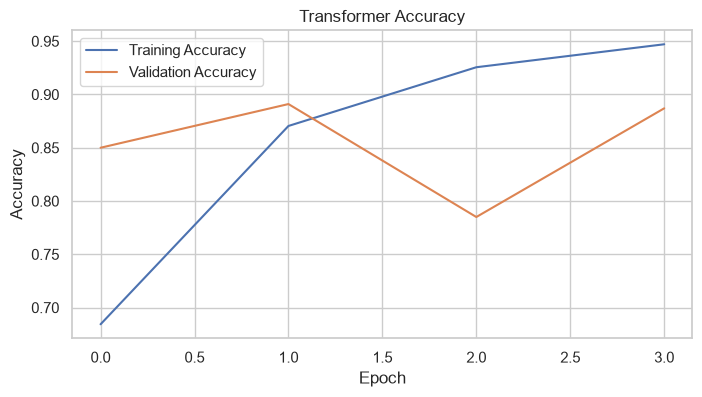

In [93]:
plt.figure(figsize=(8, 4))
plt.plot(transformer_history.history["accuracy"], label="Training Accuracy")
plt.plot(transformer_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Transformer Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## Plot training loss

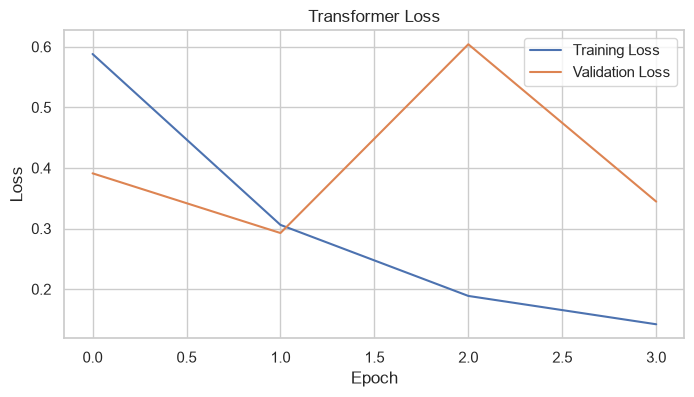

In [94]:
plt.figure(figsize=(8, 4))
plt.plot(transformer_history.history["loss"], label="Training Loss")
plt.plot(transformer_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Transformer Loss")
plt.legend()
plt.grid(True)
plt.show()

## Evaluate the model

In [96]:
from tensorflow.keras.metrics import AUC

transformer_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", AUC(name="auc")]
)

test_loss, test_accuracy, test_auc = transformer_model.evaluate(
    x_test, y_test, verbose=0
)

# Print evaluation results
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test ROC-AUC: {test_auc:.4f}")

Test Loss: 0.3298
Test Accuracy: 0.8630
Test ROC-AUC: 0.9370


In [97]:
y_probability = transformer_model.predict(x_test, verbose=0).ravel()

y_prediction = (y_probability >= 0.5).astype(int)

print("Probabilities:", y_probability[:10])
print("Predictions:", y_prediction[:10])

Probabilities: [0.30253762 0.9994192  0.82409203 0.7065971  0.96743363 0.578047
 0.9313575  0.01921738 0.98007345 0.99477476]
Predictions: [0 1 1 1 1 1 1 0 1 1]


## Classification report

In [98]:
print(classification_report(
    y_test,
    y_prediction,
    target_names=["Negative", "Positive"]
))

              precision    recall  f1-score   support

    Negative       0.90      0.82      0.86      1566
    Positive       0.83      0.91      0.86      1434

    accuracy                           0.86      3000
   macro avg       0.86      0.86      0.86      3000
weighted avg       0.87      0.86      0.86      3000



## Confusion matrix

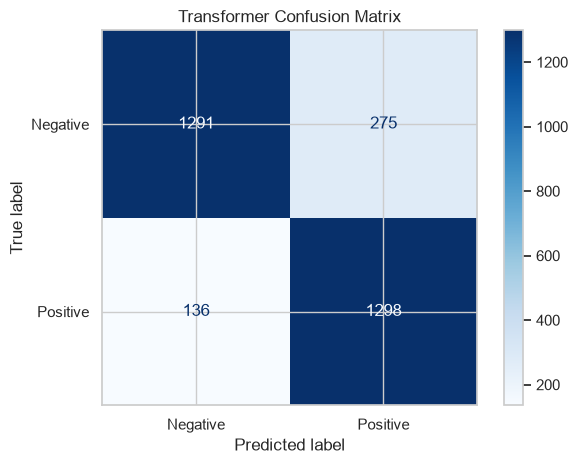

In [99]:
cm = confusion_matrix(y_test, y_prediction, labels=[0, 1])
cm_display = ConfusionMatrixDisplay(
            confusion_matrix=cm, 
            display_labels=["Negative", "Positive"]
        )
cm_display.plot(cmap="Blues", values_format="d")

plt.title("Transformer Confusion Matrix")
plt.tight_layout()
plt.show()

## ROC curve

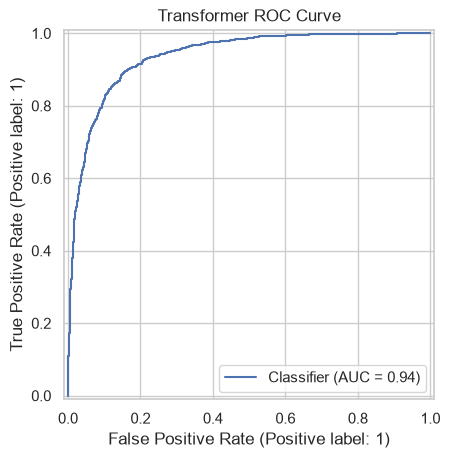

In [ ]:
RocCurveDisplay.from_predictions(y_test, y_probability)

plt.title("Transformer ROC Curve")
plt.grid(True)
plt.show()


## Predict sentiment for example reviews

##  Load IMDB Word Index

In [101]:
word_index = keras.datasets.imdb.get_word_index()

word_index = {word: index + 3 for word, index in word_index.items()}

word_index["<PAD>"] = 0
word_index["<START>"] = 1
word_index["<UNK>"] = 2
word_index["<UNUSED>"] = 3

print("IMDB word index loaded successfully!")

IMDB word index loaded successfully!


## Encode and Pad Example Reviews

In [102]:
sample_reviews = [
    "this movie was great and enjoyable",
    "this movie was boring and bad"
]

sample_sequences = []

for review in sample_reviews:

    words = review.lower().split()
    sequence = [1]

    for word in words:
        sequence.append(word_index.get(word, 2))

    sequence = [
        index if index < VOCAB_SIZE else 2
        for index in sequence
    ]

    sample_sequences.append(sequence)

sample_padded = keras.utils.pad_sequences(
    sample_sequences,
    maxlen=MAX_LEN,
    padding="pre",
    truncating="pre"
)

# Display the padded data shape
print("Padded review shape:", sample_padded.shape)

Padded review shape: (2, 200)


## Predict Sentiment

In [103]:
sample_probabilities = transformer_model.predict(
    sample_padded,
    verbose=0
).ravel()

for review, probability in zip(sample_reviews, sample_probabilities):

    sentiment = "Positive" if probability >= 0.5 else "Negative"

    print("Review:", review)

    print(f"Positive probability: {probability:.4f}")

    print("Predicted sentiment:", sentiment)

    print("-" * 35)

Review: this movie was great and enjoyable
Positive probability: 0.7996
Predicted sentiment: Positive
-----------------------------------
Review: this movie was boring and bad
Positive probability: 0.2218
Predicted sentiment: Negative
-----------------------------------


## Prepare Question Results

In [104]:
question_numbers = list(range(1, 11))

confidence_scores = [0.95, 0.82, 0.67, 0.91, 0.45,
                     0.78, 0.88, 0.52, 0.96, 0.73]

correct_answers = [True, True, False, True, False,
                   True, True, False, True, True]

for i in range(10):
    print(
        f"Question {question_numbers[i]}: "
        f"Confidence = {confidence_scores[i]:.2f}, "
        f"Correct = {correct_answers[i]}"
    )

Question 1: Confidence = 0.95, Correct = True
Question 2: Confidence = 0.82, Correct = True
Question 3: Confidence = 0.67, Correct = False
Question 4: Confidence = 0.91, Correct = True
Question 5: Confidence = 0.45, Correct = False
Question 6: Confidence = 0.78, Correct = True
Question 7: Confidence = 0.88, Correct = True
Question 8: Confidence = 0.52, Correct = False
Question 9: Confidence = 0.96, Correct = True
Question 10: Confidence = 0.73, Correct = True


## Plot Horizontal Bar Chart

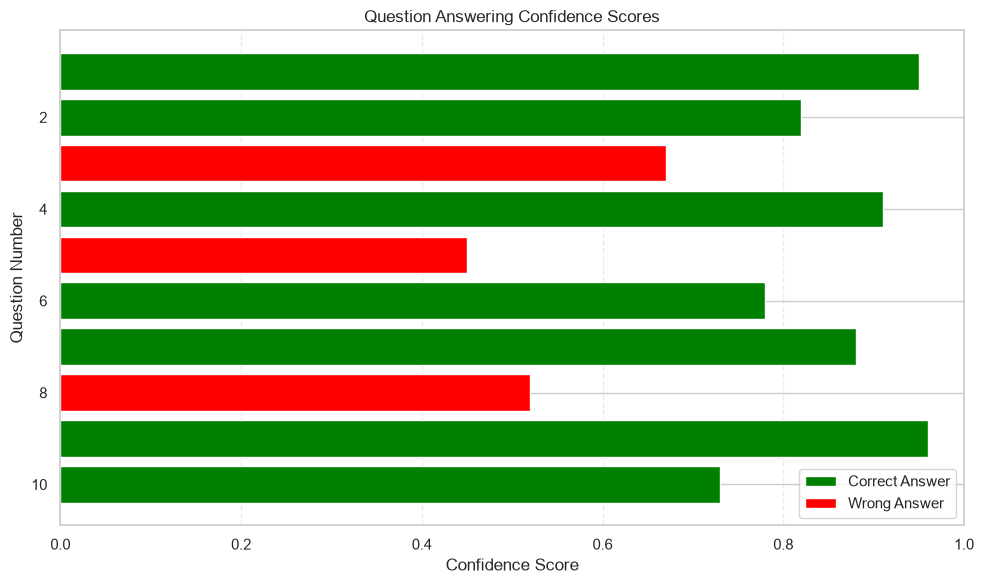

In [105]:
bar_colors = [
    "green" if correct else "red"
    for correct in correct_answers
]

plt.figure(figsize=(10, 6))
plt.barh(
    question_numbers,
    confidence_scores,
    color=bar_colors
)

plt.title("Question Answering Confidence Scores")
plt.xlabel("Confidence Score")
plt.ylabel("Question Number")

plt.xlim(0, 1)

plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle="--", alpha=0.4)
from matplotlib.patches import Patch

legend_items = [
    Patch(facecolor="green", label="Correct Answer"),
    Patch(facecolor="red", label="Wrong Answer")
]

plt.legend(handles=legend_items)
plt.tight_layout()
plt.show()

## Save the trained Transformer

## Fix the custom layer

In [108]:
@keras.utils.register_keras_serializable()
class TokenAndPositionEmbedding(layers.Layer):

    def __init__(self, max_length, vocabulary_size, embedding_dim, **kwargs):
        super().__init__(**kwargs)

        # Store the configuration values
        self.max_length = max_length
        self.vocabulary_size = vocabulary_size
        self.embedding_dim = embedding_dim

        # Create token embedding layer
        self.token_embedding = layers.Embedding(
            input_dim=vocabulary_size,
            output_dim=embedding_dim
        )

        # Create position embedding layer
        self.position_embedding = layers.Embedding(
            input_dim=max_length,
            output_dim=embedding_dim
        )

    def call(self, inputs):

        sequence_length = tf.shape(inputs)[-1]
        positions = tf.range(sequence_length)
        token_embeddings = self.token_embedding(inputs)
        position_embeddings = self.position_embedding(positions)
        return token_embeddings + position_embeddings

    def get_config(self):
        config = super().get_config()

        config.update({
            "max_length": self.max_length,
            "vocabulary_size": self.vocabulary_size,
            "embedding_dim": self.embedding_dim
        })

        return config

In [109]:
transformer_model.save("transformer_imdb_sentiment_model.keras")

print("Saved model: transformer_imdb_sentiment_model.keras")

Saved model: transformer_imdb_sentiment_model.keras


In [110]:
loaded_transformer_model = keras.models.load_model(
    "transformer_imdb_sentiment_model.keras",
    custom_objects={
        "TokenAndPositionEmbedding": TokenAndPositionEmbedding,
        "TransformerEncoder": transformer_encoder
    }
)
loaded_loss, loaded_accuracy, loaded_auc = loaded_transformer_model.evaluate(x_test, y_test, verbose=0)

print(f"Loaded model test accuracy: {loaded_accuracy:.4f}")
print(f"Loaded model test ROC-AUC: {loaded_auc:.4f}")

C:\Users\Santosh verma\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\layer.py:431: UserWarning: `build()` was called on layer 'token_and_position_embedding_4', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
C:\Users\Santosh verma\AppData\Roaming\Python\Python312\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_4', because it has 42 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


Loaded model test accuracy: 0.8630
Loaded model test ROC-AUC: 0.9370


In [111]:
# Evaluate the loaded model
loaded_loss, loaded_accuracy, loaded_auc = (
    loaded_transformer_model.evaluate(
        x_test, y_test, verbose=0
    )
)

# Print test results
print(f"Loaded model test loss: {loaded_loss:.4f}")
print(f"Loaded model test accuracy: {loaded_accuracy:.4f}")
print(f"Loaded model test ROC-AUC: {loaded_auc:.4f}")

Loaded model test loss: 0.3298
Loaded model test accuracy: 0.8630
Loaded model test ROC-AUC: 0.9370


# Visualise & Reflect

### 1. Encoder Model (BERT) vs Decoder Model (GPT)

- **Encoder models (BERT-style):** Read the input using bidirectional context, considering words before and after a token. They are useful for classification, text understanding, and extractive question answering.
- **Decoder models (GPT-style):** Generate text one token at a time, using previously generated tokens to predict the next token. They are useful for text generation, conversation, and summarisation.

### 2. What Is Self-Attention?

Self-attention is a mechanism that helps a model understand relationships between words in a sequence. It assigns different attention weights to tokens so the model can focus on relevant words when processing a sentence.

### 3. What Does Extractive Question Answering Mean?

Extractive question answering finds the answer directly within a given context. Instead of creating a completely new answer, the model identifies the relevant text span from the supplied passage.

### 4. What Does Temperature Control?

Temperature controls the randomness of token selection during text generation.

- **Low temperature:** Usually produces more predictable and consistent text.
- **High temperature:** Usually produces more varied and creative text, but can increase unpredictability.

Temperature does not guarantee factual accuracy.

### 5. Why Can Generated Text Be Fluent but Factually Wrong?

Language models learn patterns from training data and generate likely sequences of words. A response may therefore sound natural and confident even when it contains incorrect information. This can happen because of incomplete context, misleading training examples, or limitations in the model's learned knowledge.

### Conclusion

The confidence visualisation helps compare the model's confidence with answer correctness. A highly confident answer can still be wrong, so model outputs should be evaluated against reliable reference answers.
